# WR Doppelgänger

Scouts say things like "he moves like Cooper Kupp." This notebook checks that idea with tracking data.

We turn every wide receiver's routes into a **movement fingerprint**: how fast he gets off the line, how fast he runs,
how hard he brakes, how sharply he cuts, and how straight his paths are. Then we:

1. **Check the fingerprint is real.** Can a model tell which receiver ran a route, from movement alone?
2. **Find doppelgängers.** For each receiver, who on other teams moves most like him?
3. **Find budget doppelgängers.** Which cheap receivers move like expensive stars?

**Data:** NFL Big Data Bowl, 2021 season, weeks 1–8, passing plays only. We use **player** tracking only, never the ball.

**To run:** put the raw data in `data/data/` (see `OUT_OF_REPO.md`), pick the `.venv` kernel, then *Restart & Run All*.
The whole notebook takes about a minute.

**Contents:** 1. Load · 2. Features · 3. The training data · 4. Is the fingerprint real? · 5. Is it the player or his QB?
· 6. Doppelgängers · 7. Budget doppelgängers · 8. Comparing players · 9. Did we deliver the core idea?

In [1]:
import os
import sys
from pathlib import Path

# Work from the repo root so every path matches the scripts in src/.
ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import plotly.io as pio
from IPython.display import Image, display

import load_data, features, fingerprint, doppelganger, budget, visuals

pio.renderers.default = "plotly_mimetype+notebook_connected"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 2)
OUT = ROOT / "outputs"
STAR = "Cooper Kupp"          # the player we follow through the notebook; change to explore
print("Repo root:", ROOT)
print("Raw data found:", (ROOT / "data/data/tracking").is_dir())

Repo root: c:\hack_nfl\shadow
Raw data found: True


## 1. Load the routes

We keep only **wide receivers who ran a pass route**. For each route we cut the tracking data from the **snap** to the
**throw** (or sack). Tracking is recorded 10 times per second.

We also flip plays that go to the left, so every play runs left to right.

In [2]:
load_data.build_wr_routes()
routes = pd.read_parquet(OUT / "wr_routes.parquet")
routes.head()

  loaded 20/122 games


  loaded 40/122 games


  loaded 60/122 games


  loaded 80/122 games


  loaded 100/122 games


  loaded 120/122 games
  loaded 122/122 games



WR route rows in PFF:          23,033
Plays dropped (no snap/end):   24
Routes dropped (<15 frames):  66
Routes kept:                   22,900
WRs:                           210
Frame rows:                    724,272
Frames per route:
count    22900.0
mean        31.6
std         11.4
min         15.0
25%         24.0
50%         29.0
75%         36.0
max         99.0


Duplicate rows (full):         0
Duplicate rows (route+frame):  0
Saved -> outputs\wr_routes.parquet


,gameId,playId,nflId,frameId,team,playDirection,x,y,s,a,dis,o,dir,event,snapFrame,endFrame
0,2021090900,97,35634,6,TB,right,41.04,36.77,0.48,2.61,0.04,113.75,54.53,ball_snap,6,38
1,2021090900,97,35634,7,TB,right,41.10,36.82,0.92,3.92,0.08,111.77,52.35,NaN,6,38
2,2021090900,97,35634,8,TB,right,41.20,36.90,1.49,5.17,0.12,109.27,52.50,NaN,6,38
3,2021090900,97,35634,9,TB,right,41.36,37.02,2.15,5.11,0.20,108.27,51.18,NaN,6,38
4,2021090900,97,35634,10,TB,right,41.54,37.18,2.63,4.41,0.24,106.34,49.19,NaN,6,38


## 2. Describe each route with movement features

Each route becomes one row of numbers. These describe **how** the receiver moves, never **where** he lines up:

| Feature | In plain words |
|---|---|
| `release_speed`, `release_accel` | How explosive he is in the first second |
| `top_speed`, `avg_speed` | How fast he runs |
| `max_decel` | How hard he brakes |
| `cut_sharpness`, `speed_kept_in_cut` | How sharp his biggest cut is, and how much speed he keeps through it |
| `straightness` | Straight lines (1.0) or wavy paths |
| `route_time` | How long the route lasts before the throw |

We drop routes where the QB ran (not a real route) and routes where the receiver was already moving at the snap
(that fakes a fast release).

In [3]:
features.main()

Dropped 1,235 routes on QB-run plays


Dropped 649 routes with pre-snap motion (> 2.0 yd/s at snap)


       release_speed  release_accel  top_speed  avg_speed  max_decel  cut_sharpness  speed_kept_in_cut   has_cut  straightness  route_time
count       21016.00       21016.00   21016.00   21016.00   21016.00       18177.00            5187.00  21016.00      21016.00    21016.00
mean            4.16           4.69       6.81       4.22      -2.20          38.96               0.69      0.25          0.95        3.09
std             0.95           1.06       1.35       1.10       2.58          34.37               0.41      0.43          0.09        1.09
min             0.00           0.00       0.42       0.25     -10.00           0.14               0.01      0.00          0.06        1.50
25%             3.60           4.01       5.96       3.43      -3.80          16.23               0.29      0.00          0.95        2.40
50%             4.29           4.74       6.98       4.27      -1.40          29.23               0.74      0.00          0.98        2.80
75%             4.83       

## 3. The training data

This is the exact table the model learns from. **One row = one route.** The 10 movement columns are the inputs.
The receiver's name (`nflId`) is the answer the model has to guess.

In [4]:
train = visuals.load_training()["feats"]
print(f"{len(train):,} routes  ·  {train['nflId'].nunique()} receivers  ·  {train['gameId'].nunique()} games")
train[["displayName", "team", "gameId", "playId"] + features.FEATURES].head(10)

21,016 routes  ·  209 receivers  ·  122 games


,displayName,team,gameId,playId,release_speed,release_accel,top_speed,avg_speed,max_decel,cut_sharpness,speed_kept_in_cut,has_cut,straightness,route_time
0,Antonio Brown,TB,2021090900,97,5.37,5.17,7.19,4.62,-5.6,67.26,0.44,1,0.94,3.3
1,Mike Evans,TB,2021090900,97,4.07,4.87,7.43,4.81,-2.1,50.21,1.20,1,0.95,3.3
2,Amari Cooper,DAL,2021090900,137,3.49,4.73,8.41,4.51,-2.9,28.94,NaN,0,0.98,2.6
3,CeeDee Lamb,DAL,2021090900,137,3.74,4.68,4.77,2.30,-6.1,16.92,NaN,0,0.98,2.6
4,Amari Cooper,DAL,2021090900,187,4.91,3.83,6.87,4.42,-1.4,8.72,NaN,0,1.00,2.1
5,Michael Gallup,DAL,2021090900,187,4.92,4.52,6.45,4.07,0.0,38.89,NaN,0,0.97,2.1
6,CeeDee Lamb,DAL,2021090900,187,6.10,4.67,7.28,5.36,-0.8,11.90,NaN,0,1.00,2.1
7,Amari Cooper,DAL,2021090900,282,3.56,4.52,6.37,4.39,-1.2,56.86,1.07,1,0.93,3.3
8,CeeDee Lamb,DAL,2021090900,282,5.49,5.05,8.56,6.04,-2.5,24.86,NaN,0,0.99,3.3
9,Amari Cooper,DAL,2021090900,349,3.96,4.10,7.23,4.05,0.3,46.91,1.20,1,0.92,2.6


**From raw tracking to one row.** Here is a typical route by our featured player: the path he ran, his speed every
0.1 seconds, and the row of numbers it turns into.

Saved -> outputs\route_anatomy_cooper_kupp.png


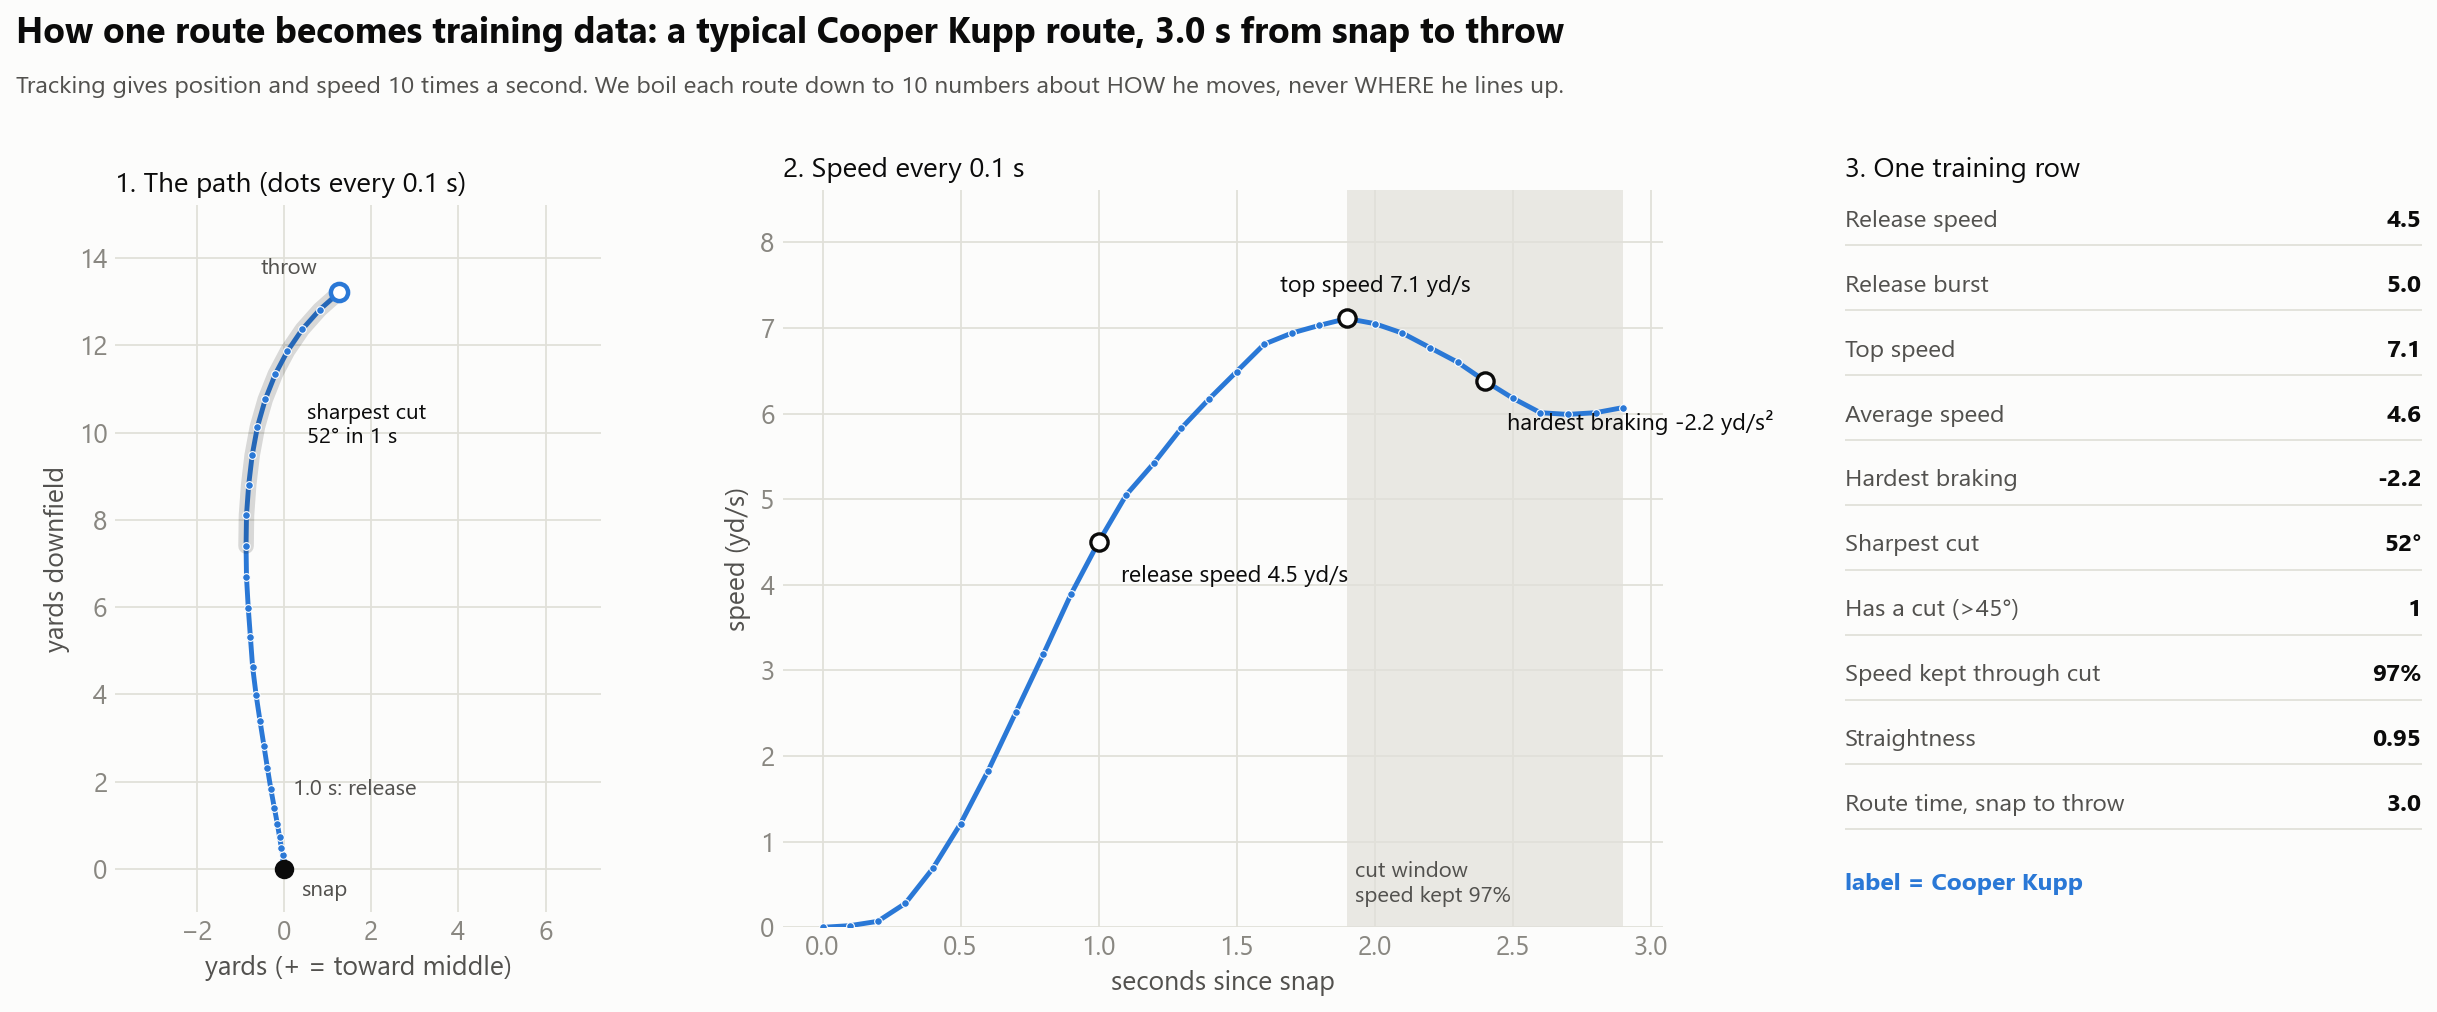

In [5]:
visuals.route_anatomy(visuals.load_training(), STAR)
display(Image(OUT / f"route_anatomy_{visuals.slug(STAR)}.png", width=1000))

**Who has enough data?** A fingerprint is an average, and an average of a few routes is noisy. So we only fingerprint
receivers with at least 80 routes.

Saved -> outputs\routes_per_wr.png


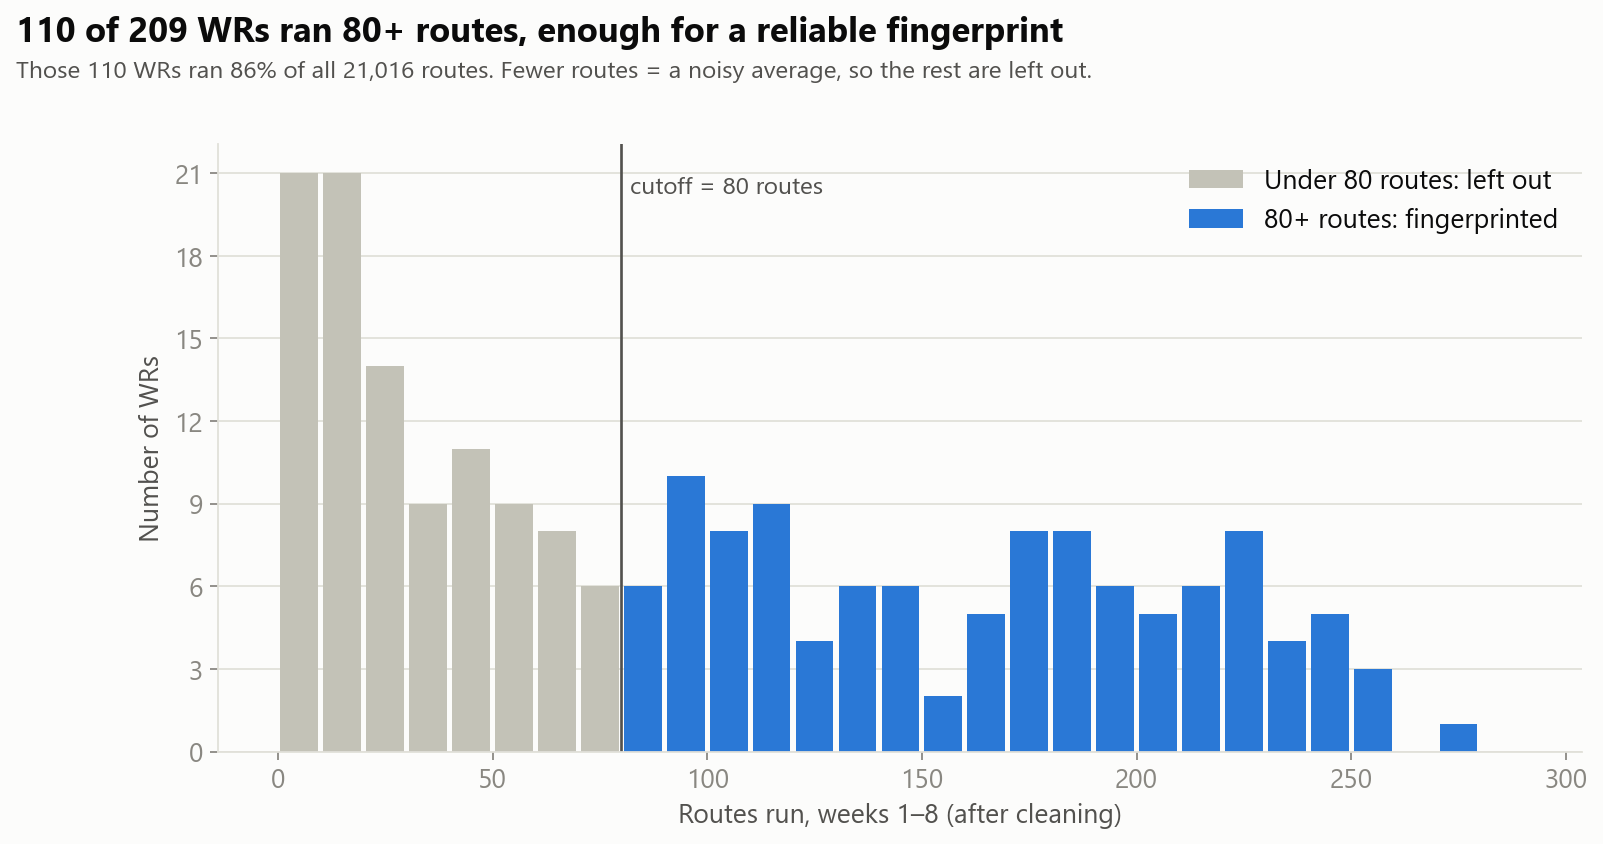

In [6]:
visuals.routes_per_wr(visuals.load_training())
display(Image(OUT / "routes_per_wr.png", width=850))

**What the numbers look like across all routes.** Most routes start around 4–5 yd/s one second after the snap,
reach about 7 yd/s, and run fairly straight. The spread is wide, which is what lets players differ.

In [7]:
train[features.FEATURES].describe().T[["mean", "std", "25%", "50%", "75%"]]

,mean,std,25%,50%,75%
release_speed,4.16,0.95,3.60,4.29,4.83
release_accel,4.69,1.06,4.01,4.74,5.36
top_speed,6.81,1.35,5.96,6.98,7.75
avg_speed,4.22,1.10,3.43,4.27,5.00
max_decel,-2.20,2.58,-3.80,-1.40,0.00
cut_sharpness,38.96,34.37,16.23,29.23,48.81
speed_kept_in_cut,0.69,0.41,0.29,0.74,1.08
has_cut,0.25,0.43,0.00,0.00,0.00
straightness,0.95,0.09,0.95,0.98,0.99
route_time,3.09,1.09,2.40,2.80,3.50


## 4. Build fingerprints and check they are real

A receiver's **fingerprint** is the average (and spread) of his route features. We use receivers with at least 80 routes.

To check the fingerprint is real, we ask: **can we tell who ran a route, on games the model never saw?**
Random guessing among 110 receivers is right about 1% of the time.

- **Season fingerprint:** build a fingerprint from half of a player's games, then find him among all 110 players using
  the other half.
- **Single route:** a model (gradient-boosted trees) guesses the player from one route only. Much harder.
- **vs. teammates:** pick between teammates only. They share the same QB and play calls, so a win here shows personal
  style, not team scheme.

Train and test are always split **by game**, so the model never sees the test games.

In [8]:
fingerprint.main()

WRs with >= 80 routes: 110   routes: 18,053

Split-half fingerprint test (20 random game halves)


  WRs with >= 20 routes in both halves: ~100

Who ran this route? (5 game splits)


  split 1: train 91 games, test 31 games / 4,631 routes


  split 2: train 91 games, test 31 games / 4,433 routes


  split 3: train 91 games, test 31 games / 4,754 routes


  split 4: train 91 games, test 31 games / 4,634 routes


  split 5: train 91 games, test 31 games / 4,739 routes

All tests on unseen games vs chance:
                                  test  accuracy    sd  chance  x_chance
         Split-half fingerprint, top-1     0.115 0.029   0.010    11.437
         Split-half fingerprint, top-5     0.327 0.046   0.050     6.522
Split-half fingerprint, teammates only     0.528 0.045   0.321     1.643
          Single route, all WRs, top-1     0.022 0.003   0.009     2.392
          Single route, all WRs, top-5     0.094 0.004   0.045     2.073
          Single route, teammates only     0.391 0.017   0.305     1.282

Signature Score = top-5 recall on unseen games, mean of 5 splits (chance 0.045).
Tiers are terciles. Order inside a tier is noise, so names are alphabetical.

DISTINCTIVE (37 WRs, 2.3x-5.1x chance), alphabetical:
  A.J. Brown (TEN), A.J. Green (ARI), Allen Robinson (CHI), Amon-Ra St. Brown (DET), Braxton Berrios (NYJ), Bryan Edwards (LV)
  Chester Rogers (TEN), Cole Beasley (BUF), Cooper Kup


Permutation importance (test log-loss increase when shuffled):
          feature  importance    std
    release_speed      0.1191 0.0047
    release_accel      0.0959 0.0018
        top_speed      0.0563 0.0067
        avg_speed      0.0266 0.0041
        max_decel      0.0214 0.0027
     straightness      0.0182 0.0020
       route_time      0.0169 0.0025
speed_kept_in_cut      0.0052 0.0017
    cut_sharpness      0.0001 0.0032
          has_cut      0.0000 0.0000

Fingerprint: 110 WRs x 28 standardized columns
Saved -> outputs/wr_fingerprints.csv, wr_fingerprints_raw.csv, signature_scores.csv, classifier_summary.csv, feature_importance.csv


**How the games are split.** One of the five train/test splits used for the single-route model:

In [9]:
f = fingerprint.load_routes()
tr, te = next(fingerprint.game_splits(f))
pd.DataFrame({"games": [tr.gameId.nunique(), te.gameId.nunique()],
              "routes": [len(tr), len(te)],
              "receivers": [tr.nflId.nunique(), te.nflId.nunique()],
              "games in both": [len(set(tr.gameId) & set(te.gameId))] * 2},
             index=["train", "test"])

,games,routes,receivers,games in both
train,91,13422,110,0
test,31,4631,90,0


**Results.** From half a season of routes, we pick the right receiver out of 110 about **11 times** more often than
guessing. A single route is too short to tell much (about 2.8 seconds of tracking).

Saved -> outputs\identification.png


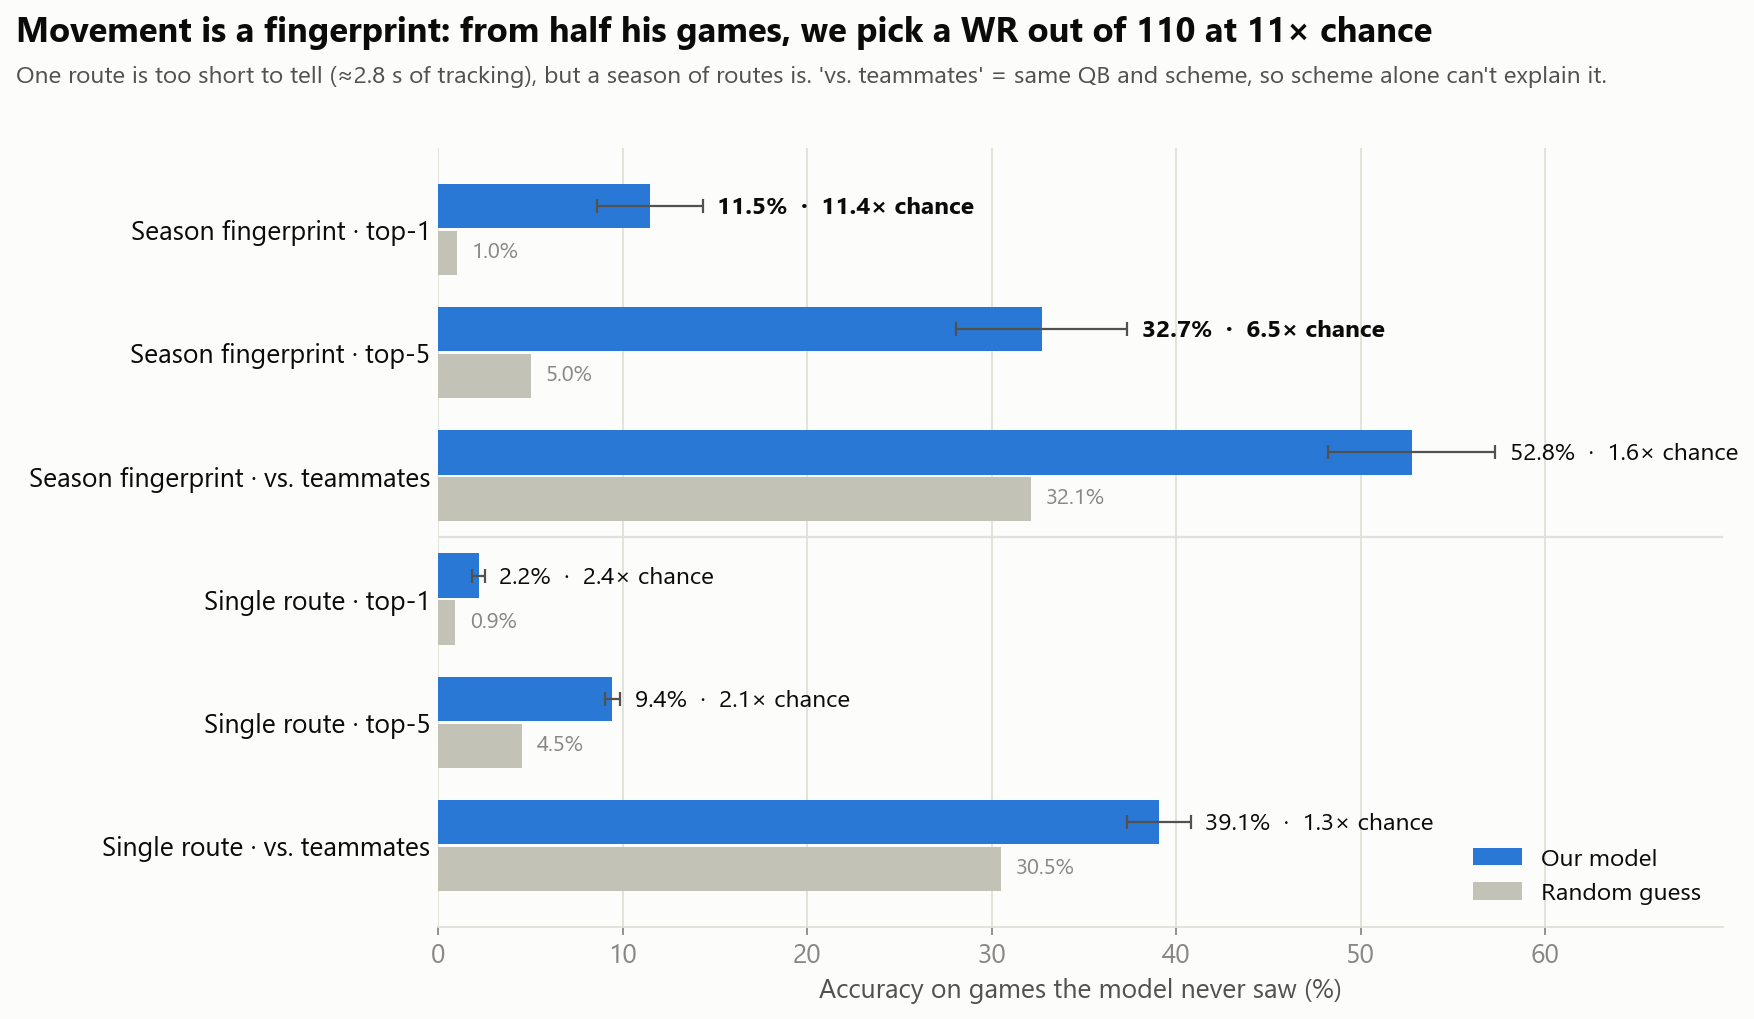

In [10]:
visuals.identification(visuals.load())
display(Image(OUT / "identification.png", width=900))

Which features matter most to the model? Speed off the line and top speed carry most of the signal.

In [11]:
pd.read_csv(OUT / "feature_importance.csv")

,feature,importance,std
0,release_speed,1.19e-01,4.73e-03
1,release_accel,9.59e-02,1.84e-03
2,top_speed,5.63e-02,6.65e-03
3,avg_speed,2.66e-02,4.11e-03
4,max_decel,2.14e-02,2.66e-03
5,straightness,1.82e-02,2.01e-03
6,route_time,1.69e-02,2.51e-03
7,speed_kept_in_cut,5.19e-03,1.71e-03
8,cut_sharpness,1.29e-04,3.17e-03
9,has_cut,0.00e+00,0.00e+00


## 5. Is it the player, or his QB?

One feature, `route_time`, depends on **when the QB throws**, not only on the receiver. If the fingerprint were mostly
QB timing, removing it would break the test. So we rerun the season test with groups of features removed.

Saved -> outputs\ablation.png


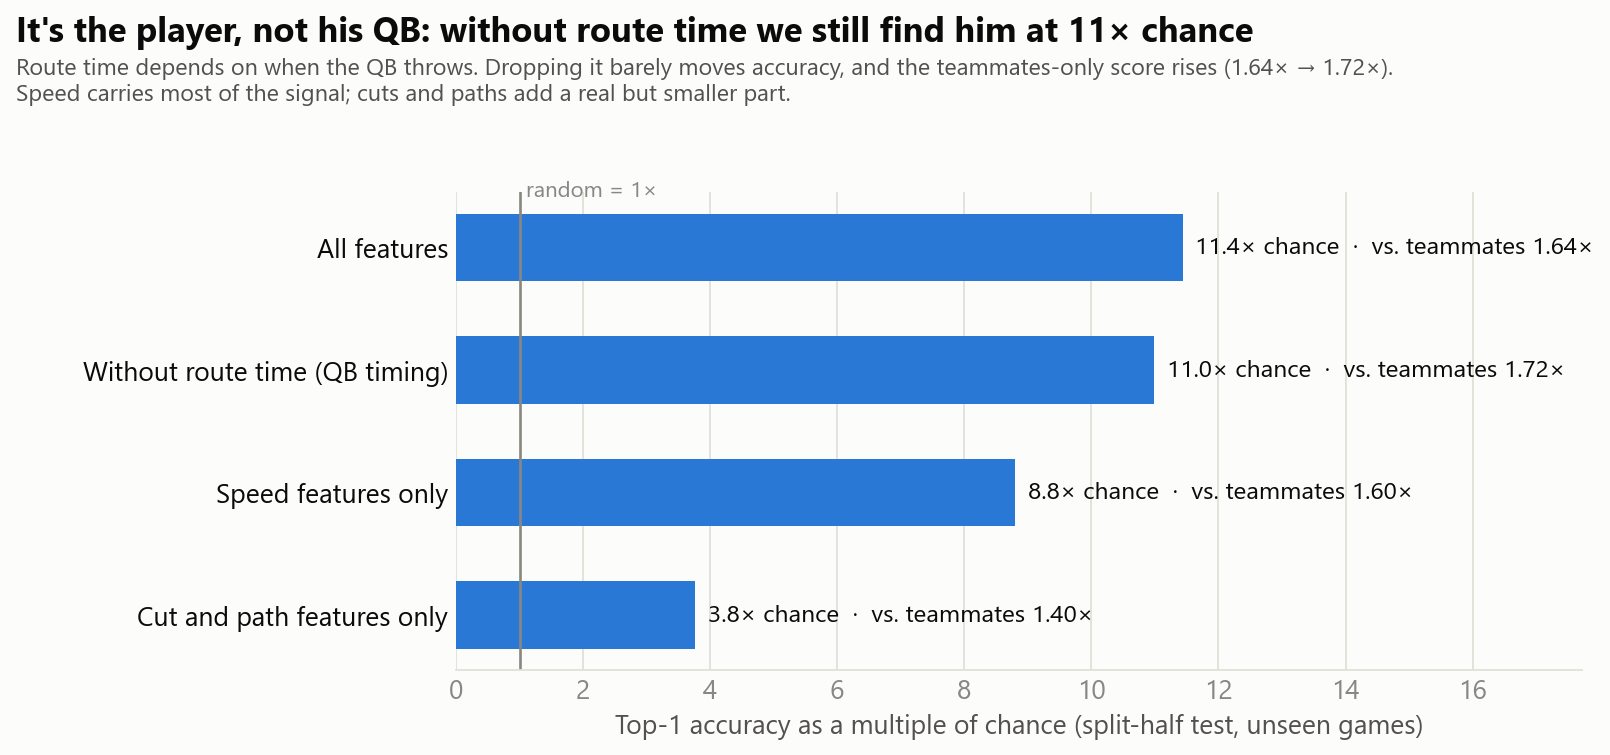

,fingerprint,top1,top1_x,top5,team,team_x
0,All features,11.5%,11.44,32.7%,52.8%,1.64
1,Without route time (QB timing),11.0%,10.99,30.9%,55.3%,1.72
2,Speed features only,8.8%,8.81,28.8%,51.4%,1.60
3,Cut and path features only,3.8%,3.76,15.8%,45.0%,1.40


In [12]:
abl = visuals.ablation(visuals.load())
display(Image(OUT / "ablation.png", width=850))
abl.assign(top1=abl.top1.map("{:.1%}".format), top5=abl.top5.map("{:.1%}".format),
           team=abl.team.map("{:.1%}".format))

**What this means:** without route time we still find the player at about 11x chance, and the teammates-only score
goes *up*. The fingerprint is the player's own movement. Speed does most of the work; cuts and path shape add a
smaller but real part.

## 6. Find doppelgängers

Two receivers are doppelgängers when their fingerprints point the same way (cosine similarity, 1.0 = identical).
We skip teammates, because they share a scheme and a GM would be shopping on other teams anyway.

Two checks on each match:
- **Stable:** split each player's games into two random halves, 20 times. A pair is *stable* if they stay in each
  other's top 5 in both halves at least half the time.
- **Hub:** some players show up in many top-5 lists. Being "his doppelgänger" says little for them, so we flag them.

In [13]:
doppelganger.main()

STABILITY, teammates excluded (20 random game halves)
  top-5 overlap between halves: 10.9% (chance 5.2%, 2.1x)
  stable top-5 pairs (both halves in >= 50% of repeats): 10 of 550

HUBS = common profile (in >= 10 top-5 lists, or named):
  Cole Beasley (12), Emmanuel Sanders (14), Hunter Renfrow (11), Jalen Guyton (10), Keelan Cole (14), Keenan Allen (17), Marquise Brown (10), Mike Evans (12), Mike Williams (10), Robby Anderson (10), Stefon Diggs (11), Tyler Lockett (12), Tyreek Hill (10)

SANITY: average gap to top-5 matches vs to a random non-teammate
  feature              top-5 gap  random gap   ratio  unit
  top_speed_mean           0.176       0.321    0.55  yd/s
  release_speed_mean       0.175       0.312    0.56  yd/s
  release_accel_mean       0.211       0.296    0.71  yd/s^2
  cut_rate                 0.037       0.066    0.55  share
  weight                  16.073      16.445    0.98  lb (not in fingerprint)
  height_in                2.518       2.599    0.97  in (not in f

**Look up any receiver.** Change the name to try another player.

In [14]:
pairs = pd.read_csv(OUT / "doppelgangers.csv")
doppelganger.find_doppelgangers(STAR, pairs=pairs)

,match_displayName,match_team,similarity,rank,built_like,stable_rate,stable,match_is_hub
0,K.J. Osborn,MIN,0.82,1,True,0.50,True,False
1,Tyler Johnson,TB,0.81,2,True,0.05,False,False
2,Keenan Allen,LAC,0.74,3,True,0.15,False,True
3,Mike Williams,LAC,0.68,4,True,0.05,False,True
4,Tee Higgins,CIN,0.66,5,True,0.05,False,False


Only show matches who are also **built like** him (within 15 lb and 2 inches):

In [15]:
doppelganger.find_doppelgangers("Stefon Diggs", k=3, pairs=pairs, built_only=True)

,match_displayName,match_team,similarity,rank,built_like,stable_rate,stable,match_is_hub
0,Chester Rogers,TEN,0.79,1,True,0.0,False,False
1,Freddie Swain,SEA,0.71,6,True,0.0,False,False
2,James Proche,BAL,0.59,10,True,0.0,False,False


**Map of all receivers.** Each dot is a receiver; dots close together move alike. Color is 2021 pay.
**Hover** over a dot to see his top 3 doppelgängers.

In [16]:
d = visuals.load()
visuals.wr_map(d).show()

Saved -> outputs\wr_map.html


## 7. Budget doppelgängers

The tracking data has no salaries, so we join 2021 contract values (average per year, APY) from OverTheCap via
nflverse. A snapshot is saved in `outputs/external/`.

For every star paid over $10M, we pick his closest match on another team who is paid less than half as much
(similarity at least 0.70, hubs skipped).

In [17]:
budget.main()

Salary match: 100.0% of 110 WRs (58 by name+birth date, 52 by unique name)
Unmatched: none
WRs with 2021 APY > $10M: 23

Spot check (APY $M, contract signed, weeks missed / on injury report / out):
   displayName team   apy contract_team  contract_signed  weeks_missed  weeks_injured  weeks_out
 Ja'Marr Chase  CIN  7.70       Bengals             2021             0              0          0
   Tyreek Hill   KC 18.00        Chiefs             2019             0              5          0
   Cooper Kupp   LA 15.75          Rams             2020             0              0          0
 Mike Williams  LAC  4.94      Chargers             2017             0              2          0
  Stefon Diggs  BUF 14.40       MIN/BUF             2018             0              5          0
 Davante Adams   GB 14.50       Packers             2017             1              1          0
Hunter Renfrow   LV  0.71       Raiders             2019             0              1          0



BUDGET DOPPELGANGERS (star APY > $10M; best non-teammate, non-hub match with sim >= 0.7 and APY < 50% of his)
            star star_team  star_apy  weeks_missed  weeks_injured  weeks_out          doppelganger dopp_team  dopp_apy  similarity  rank  stable_rate  stable  built_like  near_identical  savings
    Amari Cooper       DAL     20.00             0              2          0 Nick Westbrook-Ikhine       TEN      0.76        0.72     2         0.25   False        True           False    19.24
    Keenan Allen       LAC     20.02             0              2          0          Mohamed Sanu        SF      1.14        0.85     2         0.15   False        True           False    18.88
    Robert Woods        LA     16.25             0              0          0         Bryan Edwards        LV      1.16        0.76     1         0.10   False       False           False    15.09
   Brandin Cooks       HOU     16.20             0              4          0        Mecole Hardman        KC 

Saved -> outputs\budget_table.png  (top 10 total savings $153.3M)


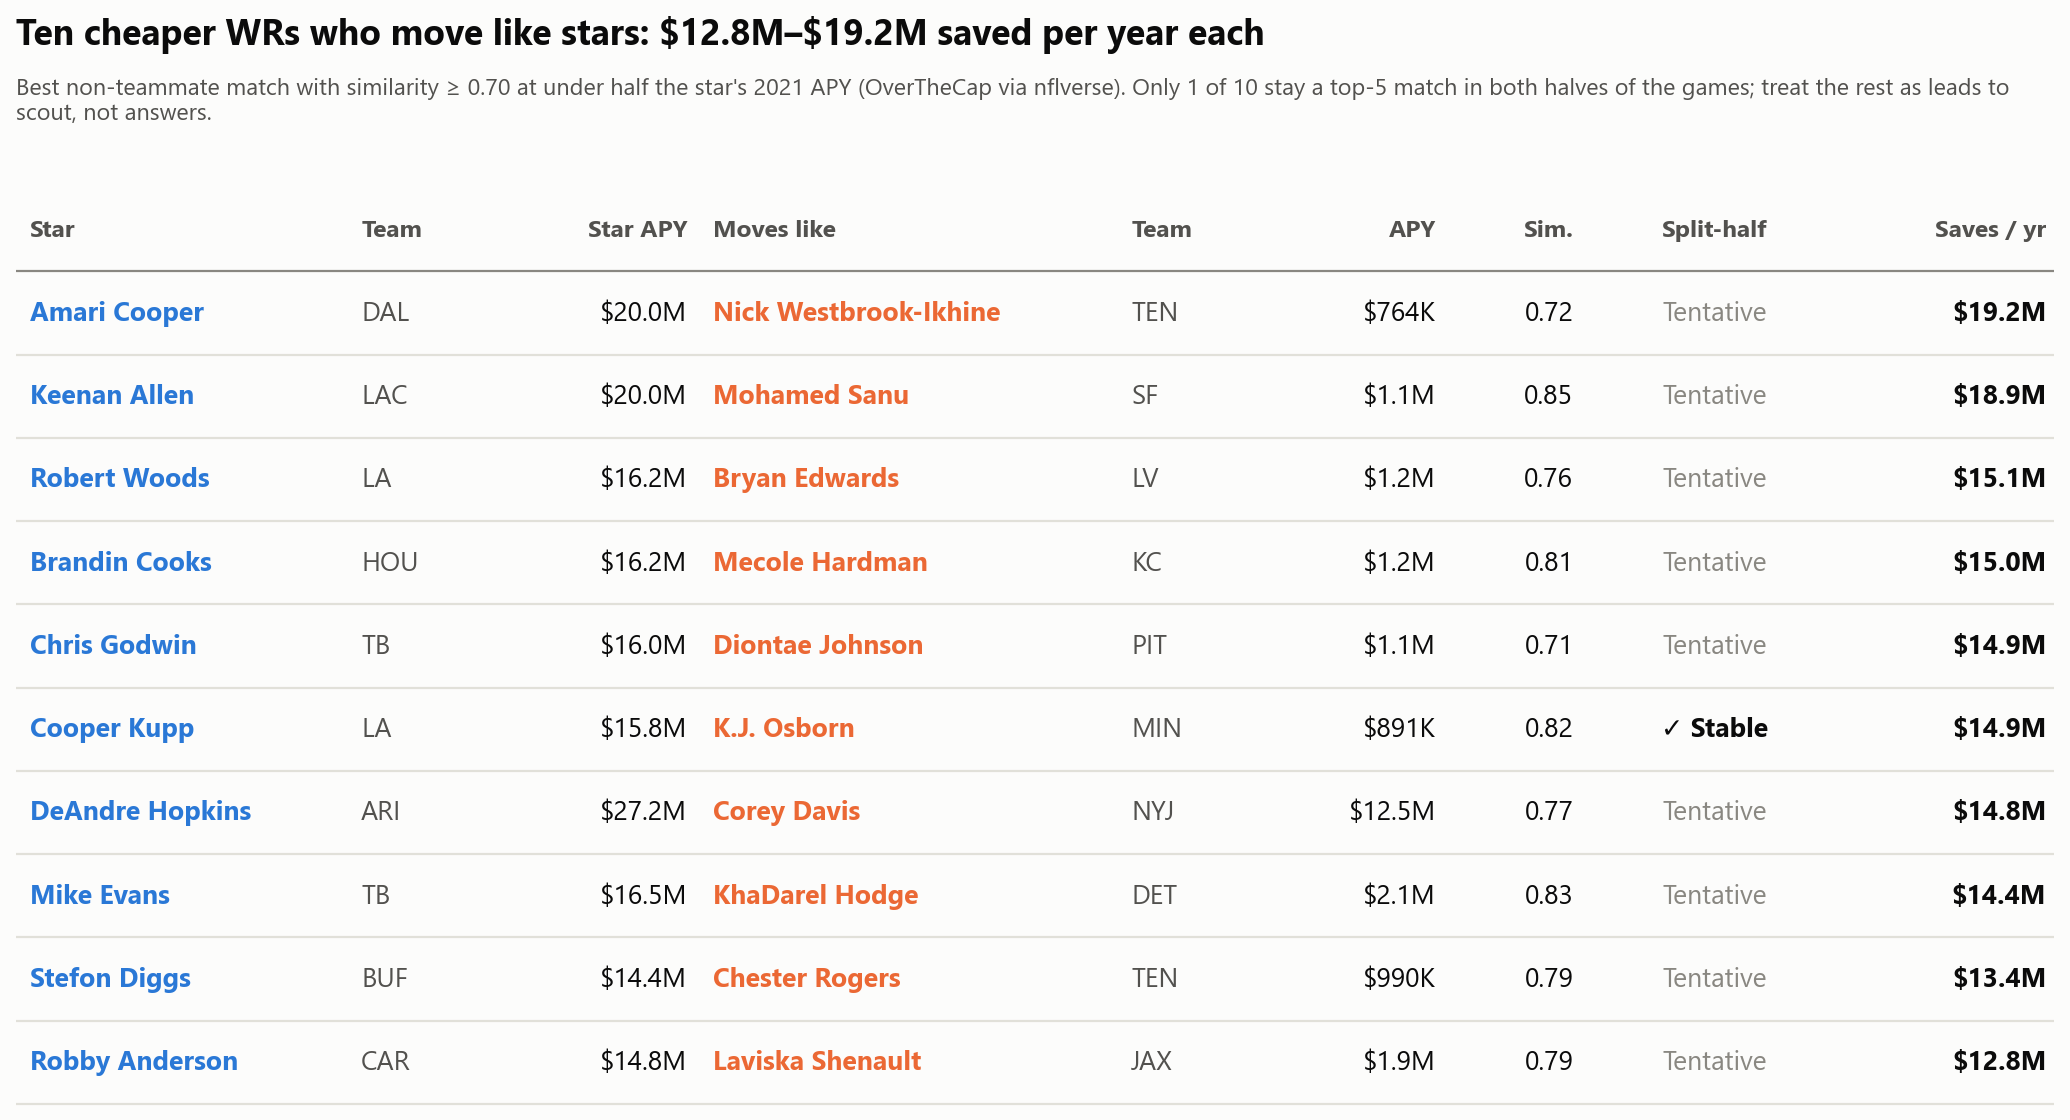

In [18]:
d = visuals.load()
visuals.budget_table(d)
display(Image(OUT / "budget_table.png", width=1000))

**Read this with care:** only Cooper Kupp → K.J. Osborn is *stable*. The other matches are good leads to scout, not
final answers.

## 8. Comparing players

Colors are the same in every chart: **blue = the star**, **orange = the player he is compared with**,
**gray = everyone else or random chance**.

### The star against his 6 closest movers

Each small chart compares the star with one match on six traits (percentile among 110 receivers).

Featured pair: Cooper Kupp -> K.J. Osborn


Saved -> outputs\compare_cooper_kupp_top6.png


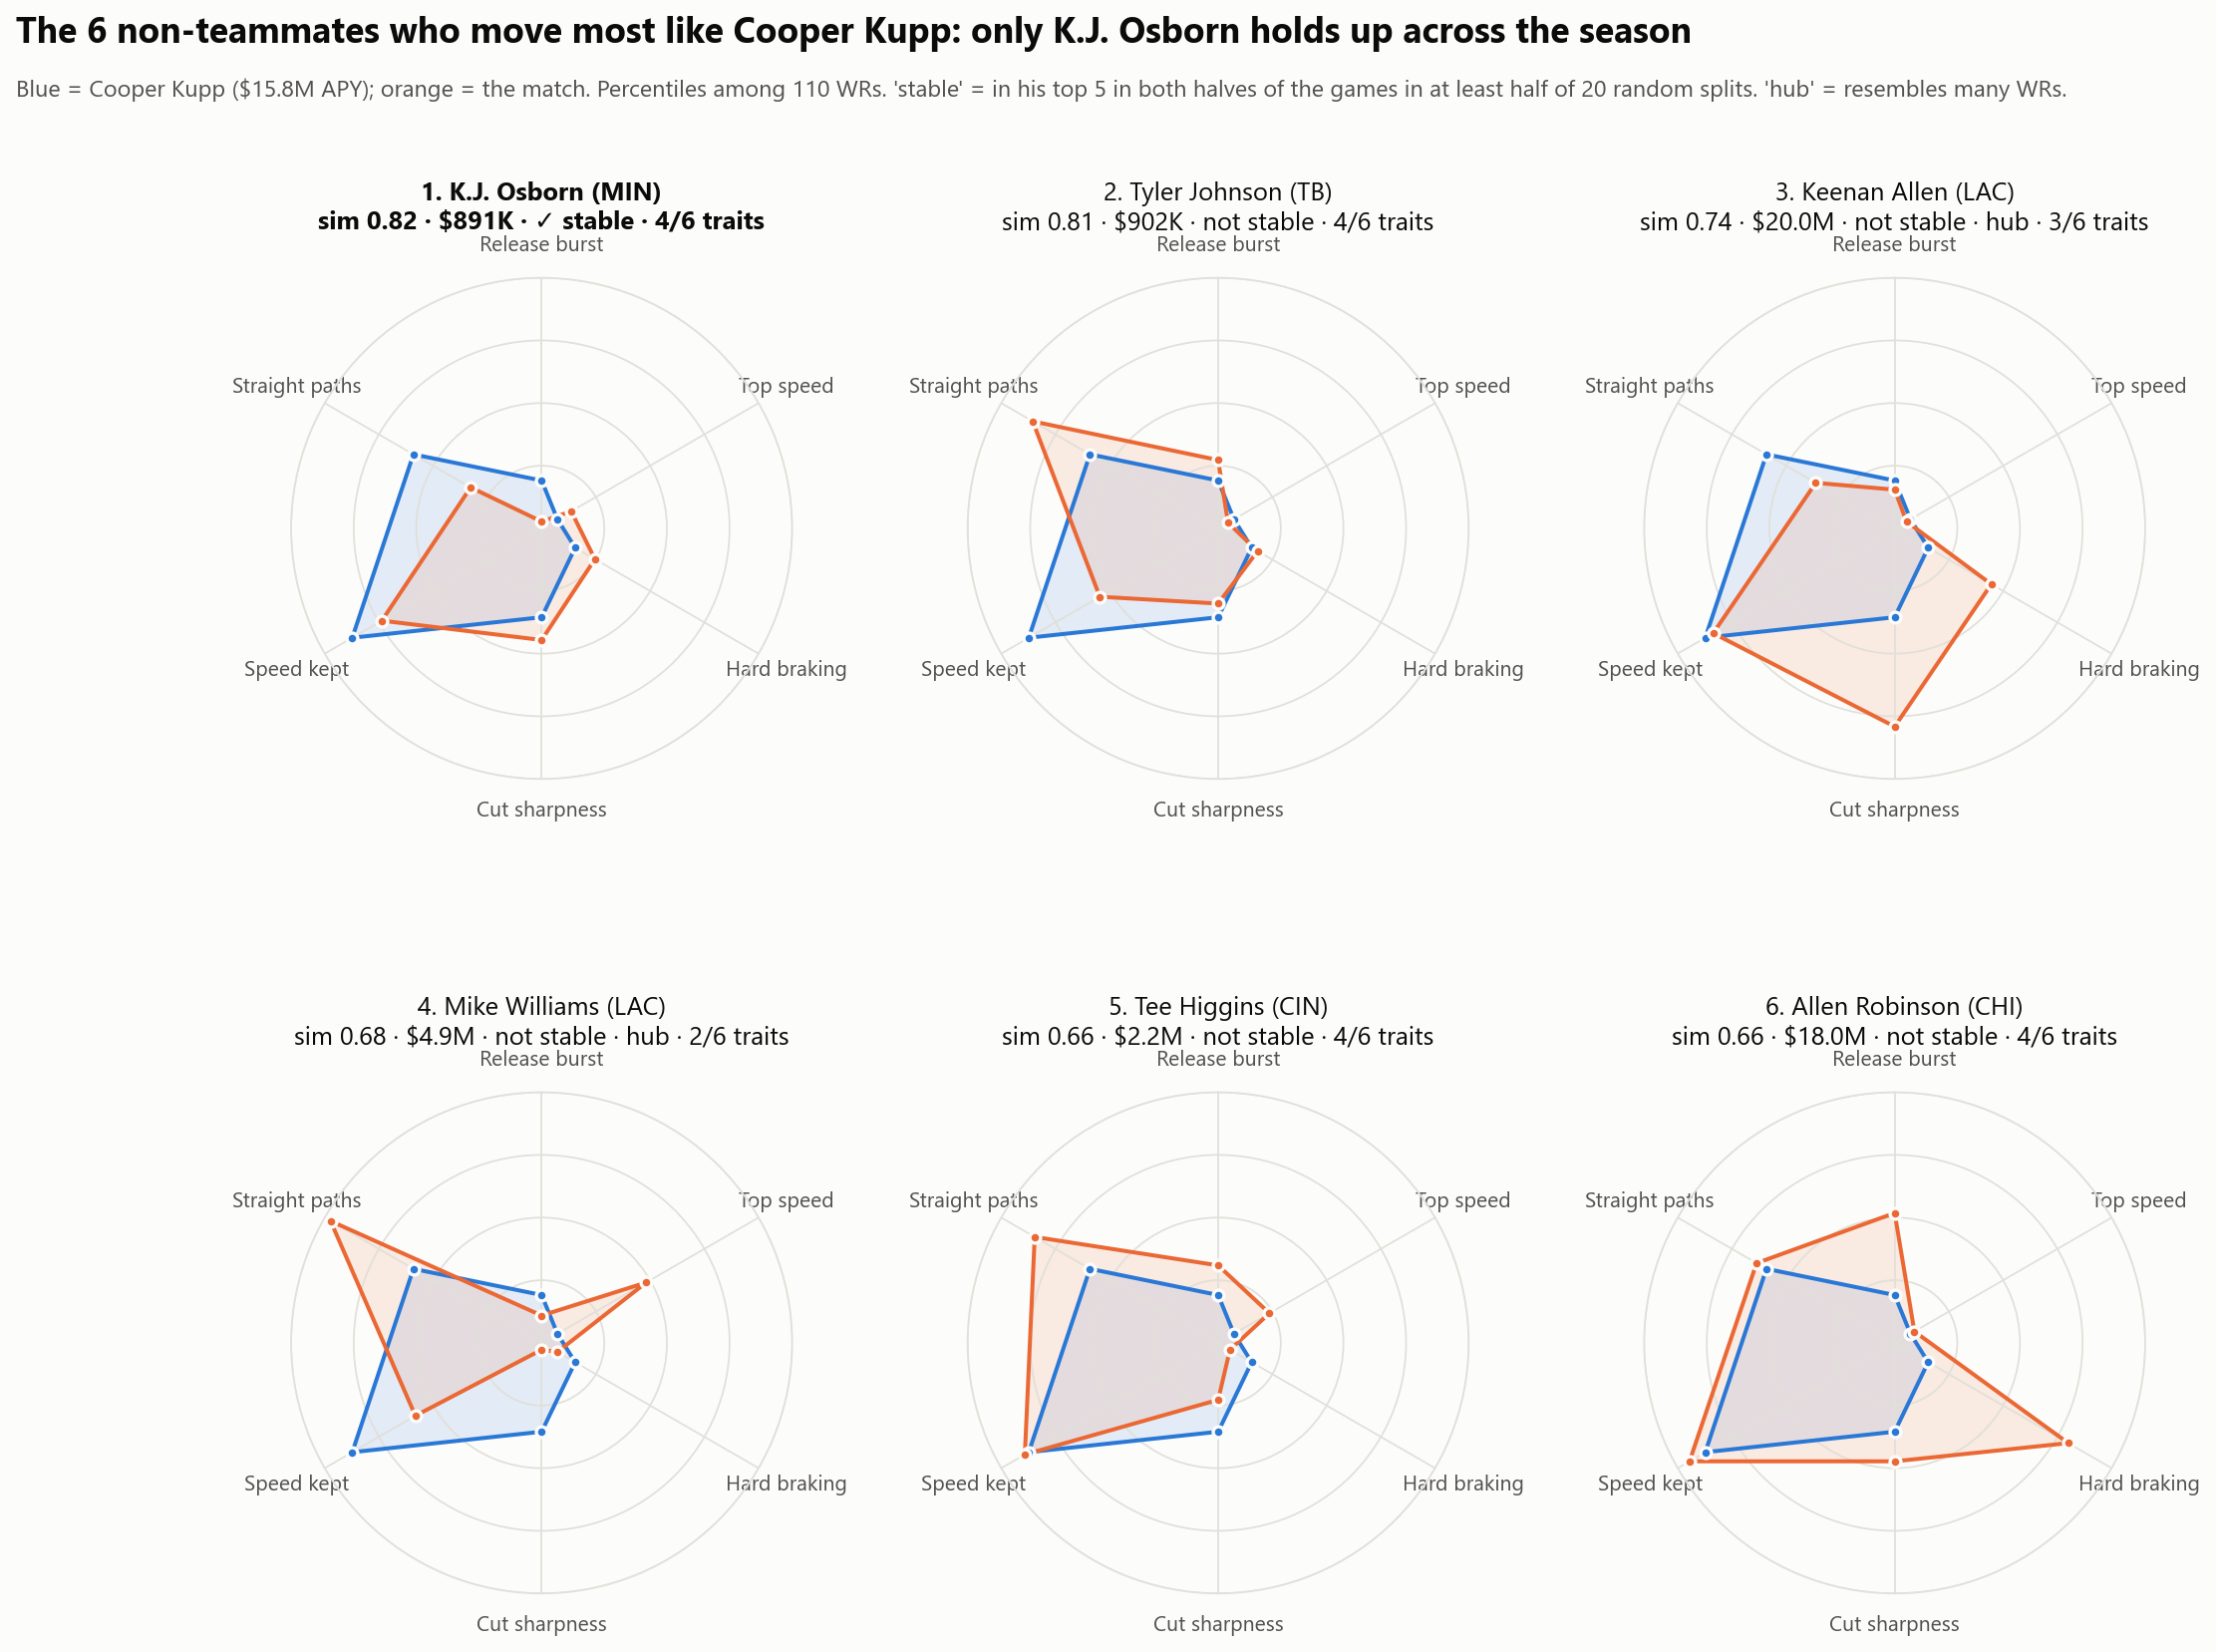

In [19]:
DOUBLE = d["budget"].set_index("star").loc[STAR, "doppelganger"]
print(f"Featured pair: {STAR} -> {DOUBLE}")
visuals.compare_matches(d, STAR)
display(Image(OUT / f"compare_{visuals.slug(STAR)}_top6.png", width=1000))

### Star vs. his budget doppelgänger, up close

Saved -> outputs\radar_cooper_kupp_vs_kj_osborn.png

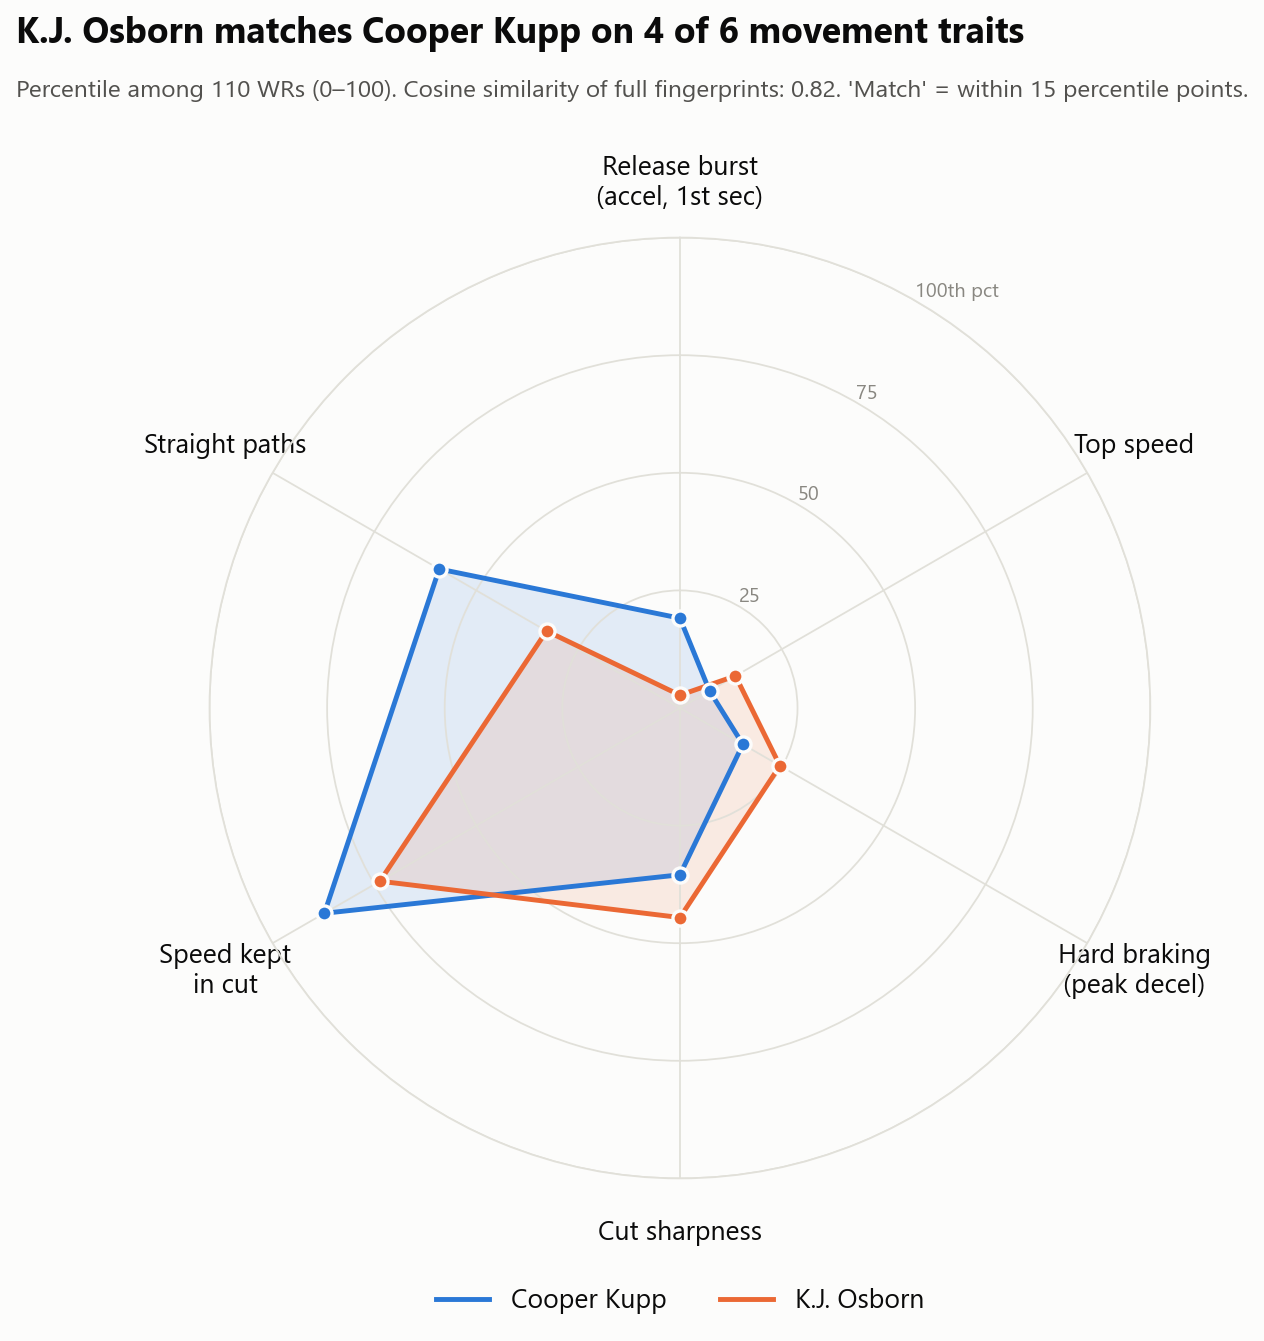

In [20]:
visuals.radar(d, STAR, DOUBLE)
display(Image(OUT / f"radar_{visuals.slug(STAR)}_vs_{visuals.slug(DOUBLE)}.png", width=600))

### Where the two sit in the training data

Gray bars are every route in the data. The lines are each player's average.

Saved -> outputs\feature_distributions_cooper_kupp_vs_kj_osborn.png


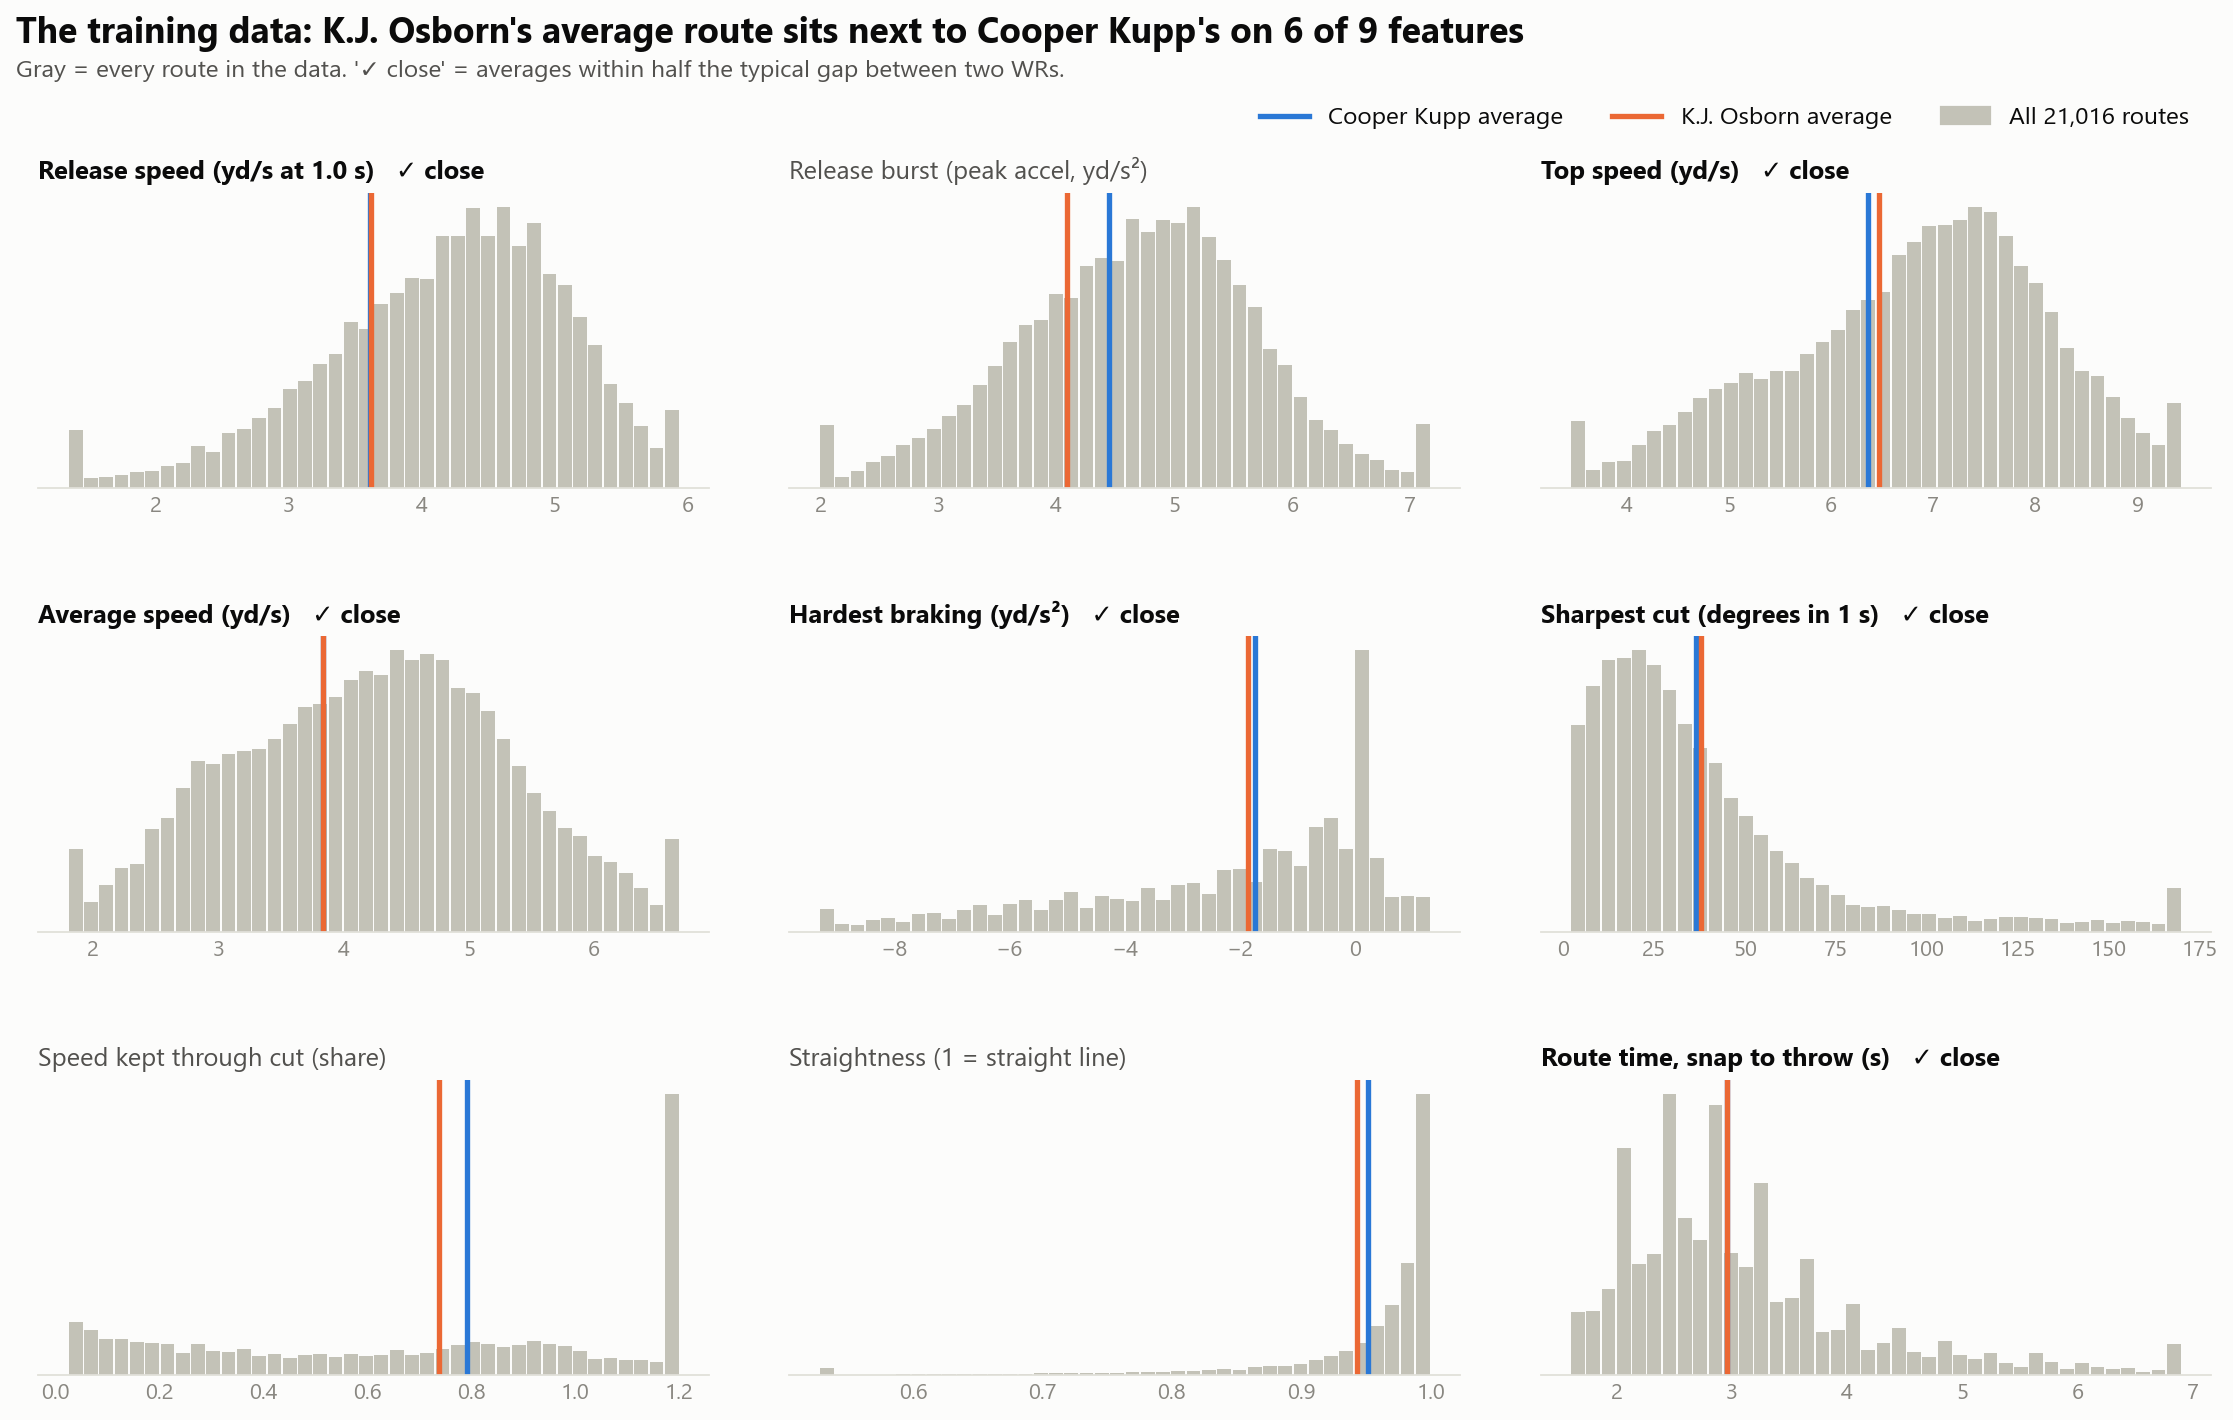

In [21]:
visuals.feature_distributions(d, STAR, DOUBLE)
display(Image(OUT / f"feature_distributions_{visuals.slug(STAR)}_vs_{visuals.slug(DOUBLE)}.png", width=1000))

### Speed over time

Average speed every 0.1 s after the snap. For contrast we also draw the star's **least** similar receiver.

Saved -> outputs\speed_profile_cooper_kupp_vs_kj_osborn.png


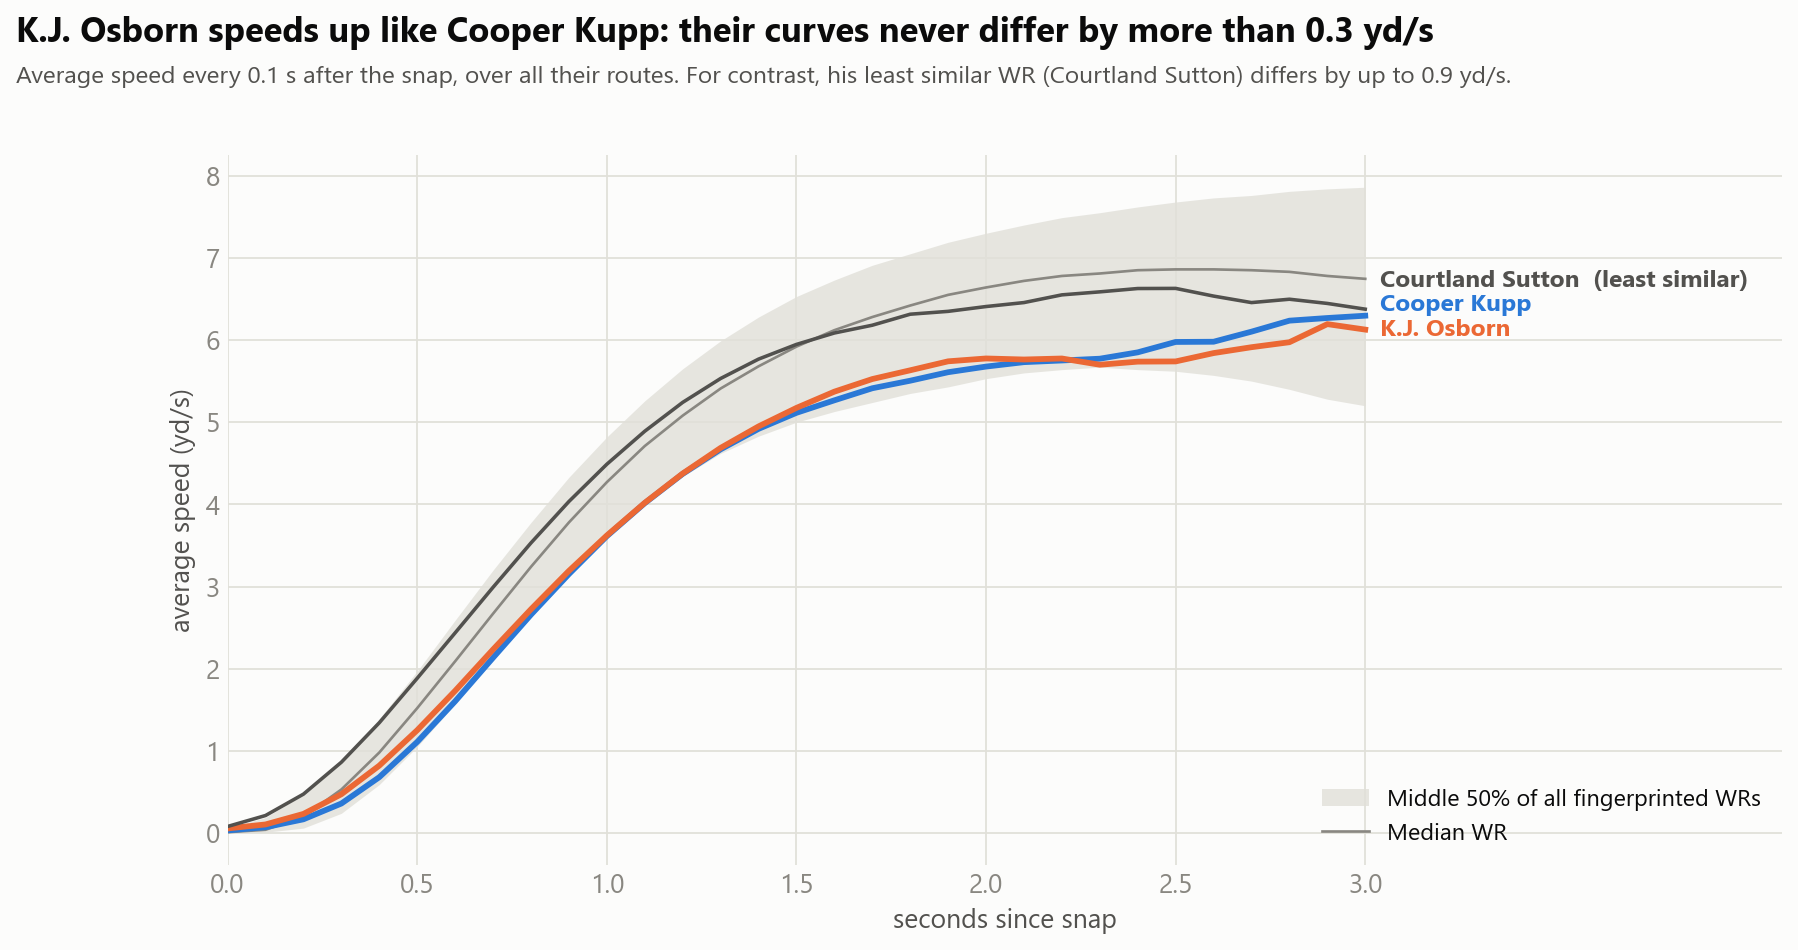

In [22]:
visuals.speed_profile(d, STAR, DOUBLE)
display(Image(OUT / f"speed_profile_{visuals.slug(STAR)}_vs_{visuals.slug(DOUBLE)}.png", width=900))

### Their routes, side by side

Ten random routes each, all moved to start at the same spot. The routes differ, but the **timing dots** (every 0.5 s)
are spaced alike, because the two players accelerate and run at the same speeds.

Saved -> outputs\route_overlay_cooper_kupp_vs_kj_osborn.png


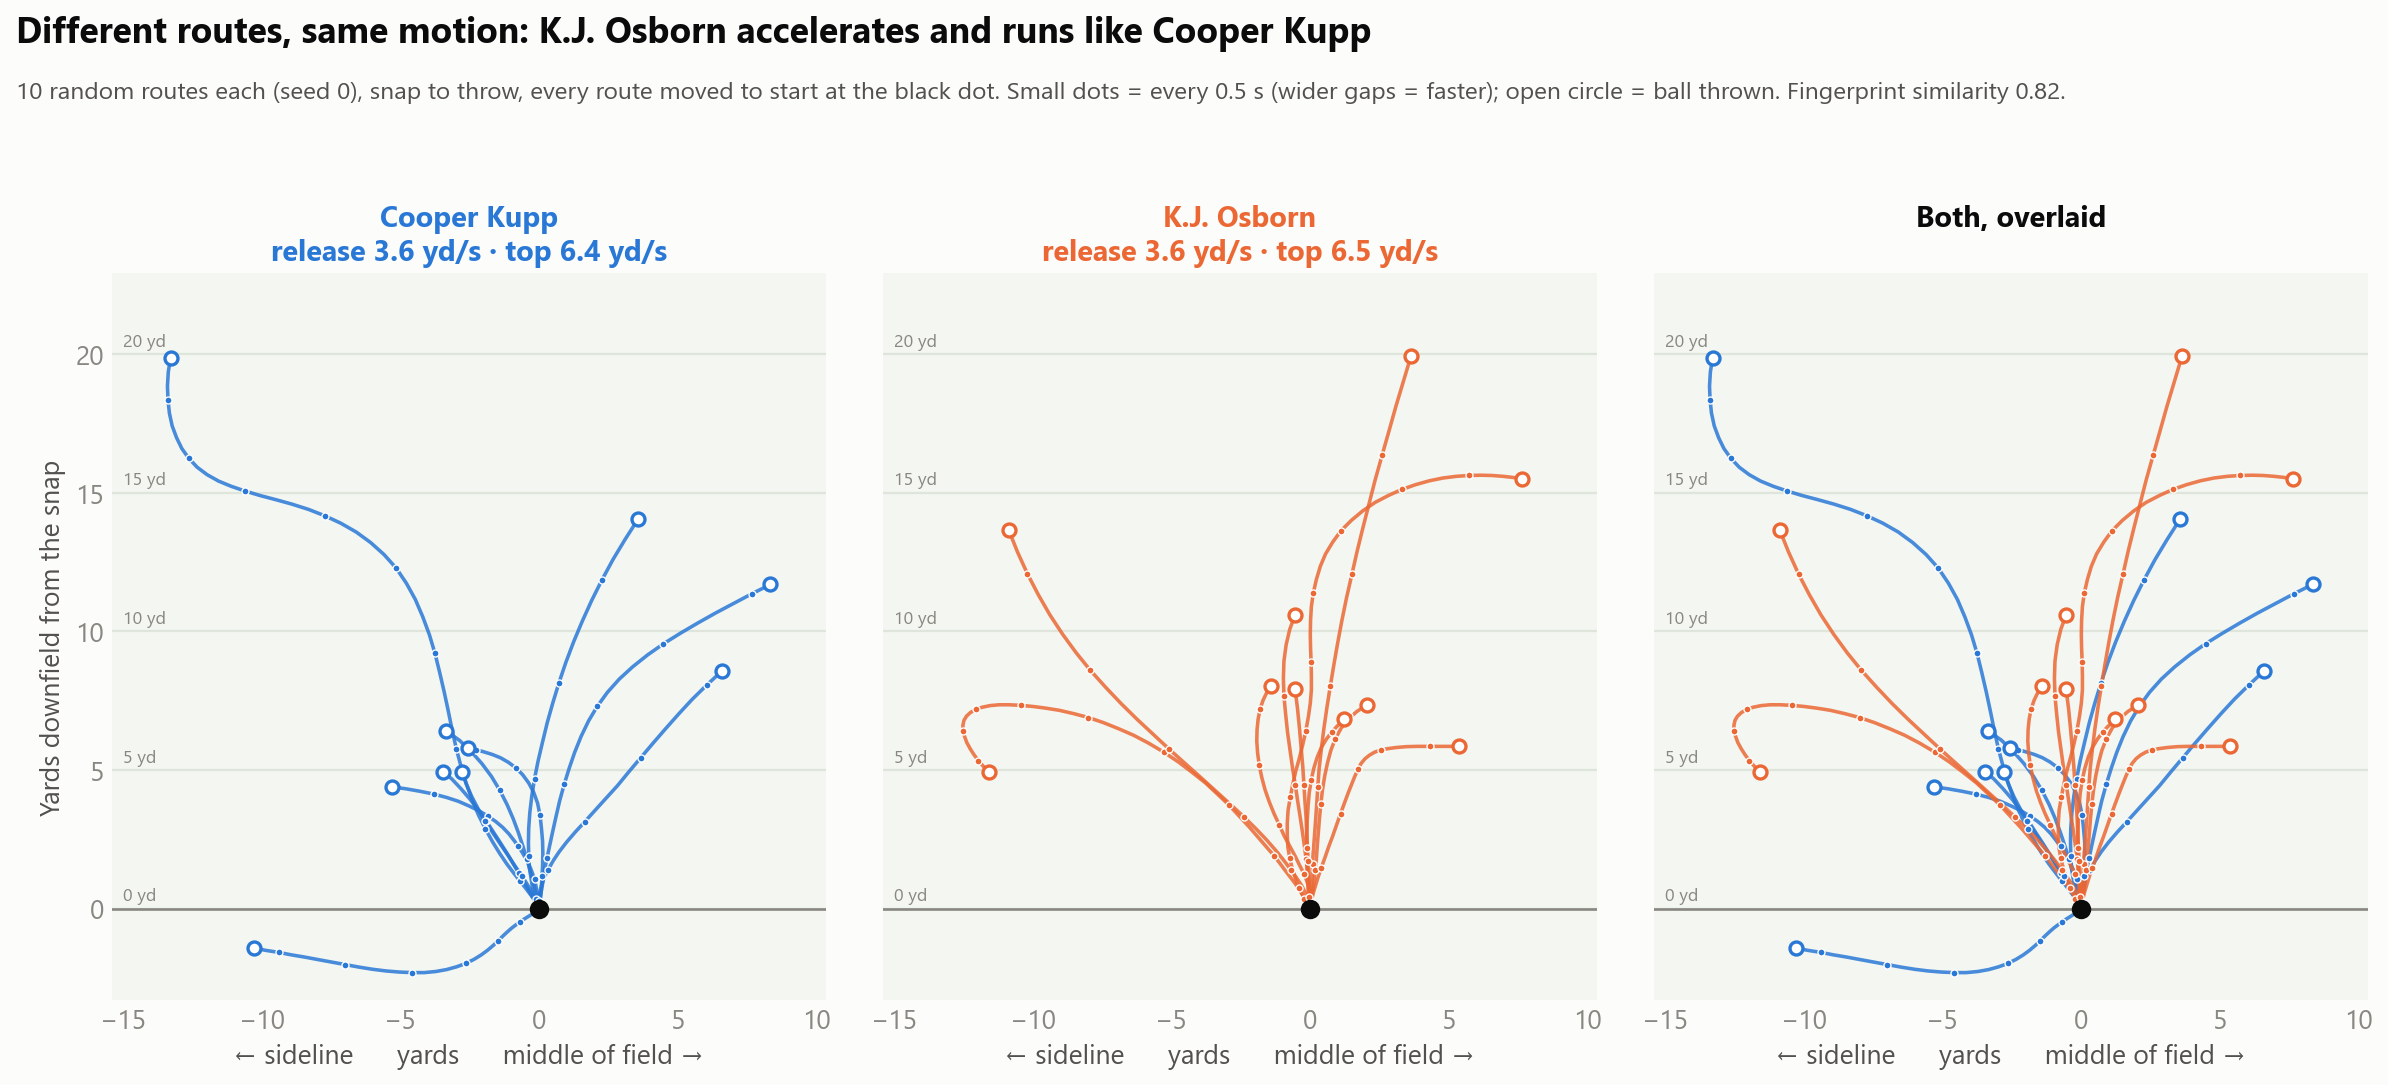

In [23]:
visuals.route_overlay(d, STAR, DOUBLE)
display(Image(OUT / f"route_overlay_{visuals.slug(STAR)}_vs_{visuals.slug(DOUBLE)}.png", width=1000))

### A second star: Justin Jefferson

The same comparison for another player. Change the name to explore anyone with 80+ routes.

Saved -> outputs\compare_justin_jefferson_top6.png


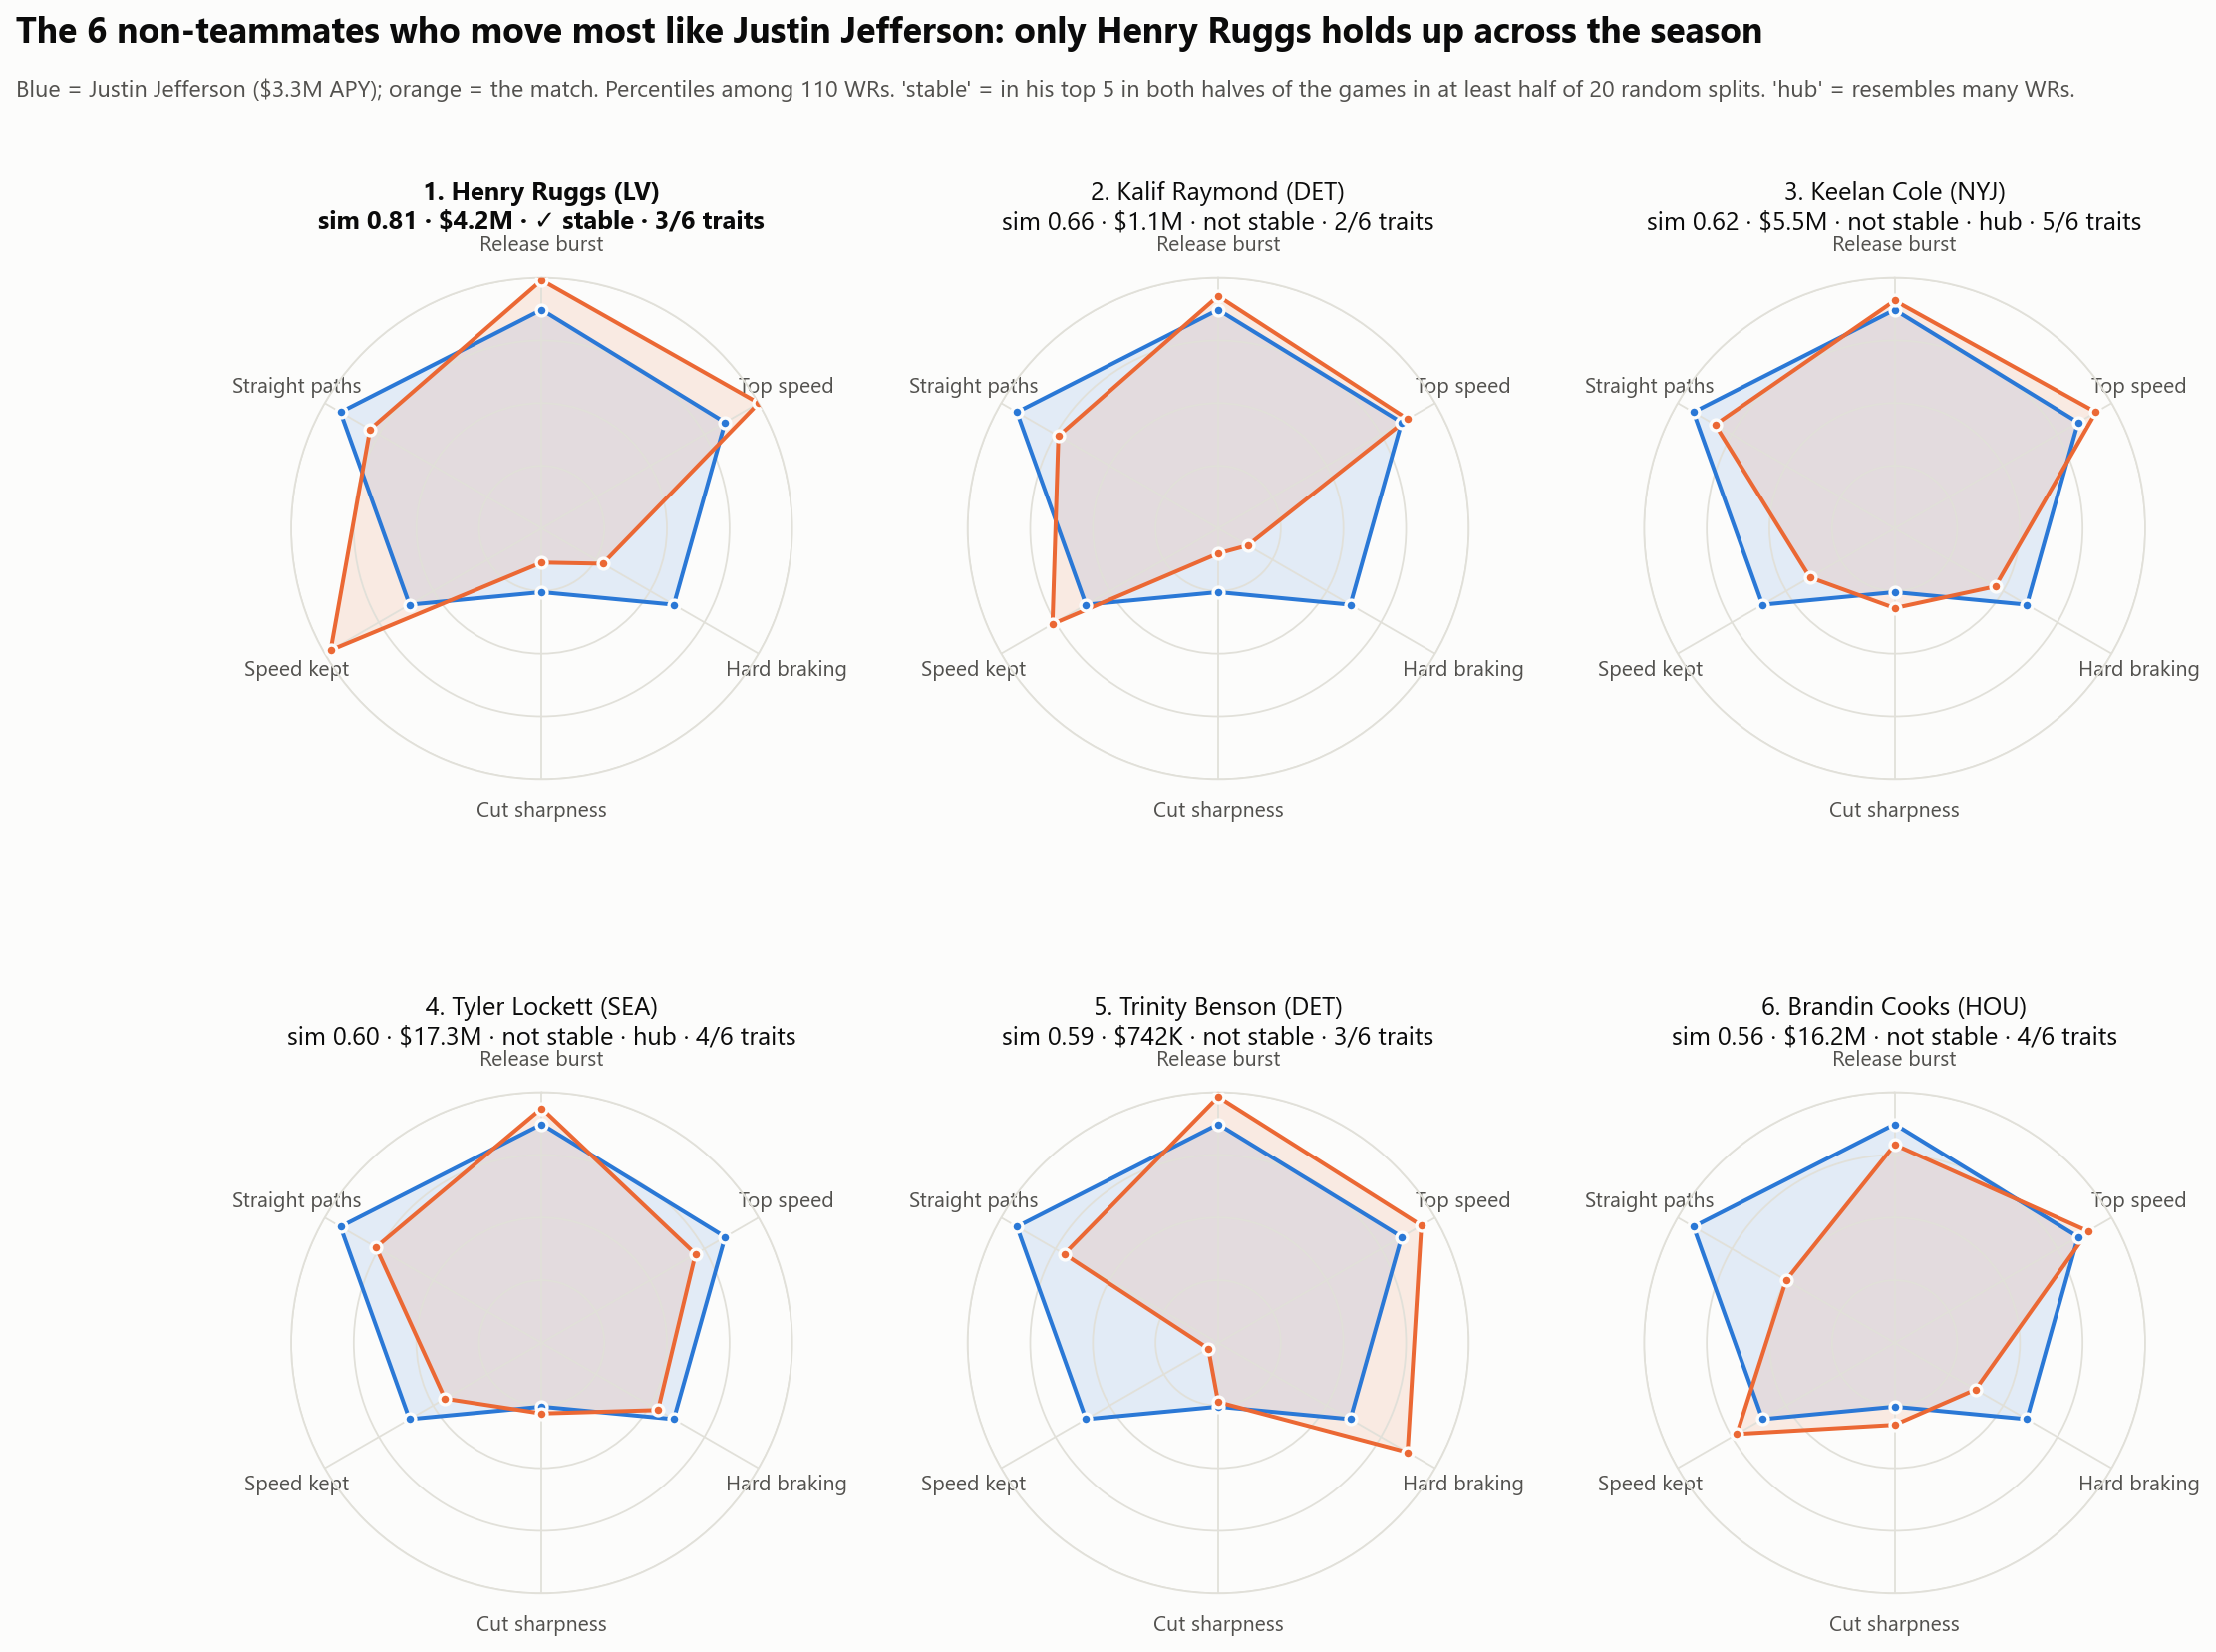

Saved -> outputs\speed_profile_justin_jefferson_vs_henry_ruggs.png


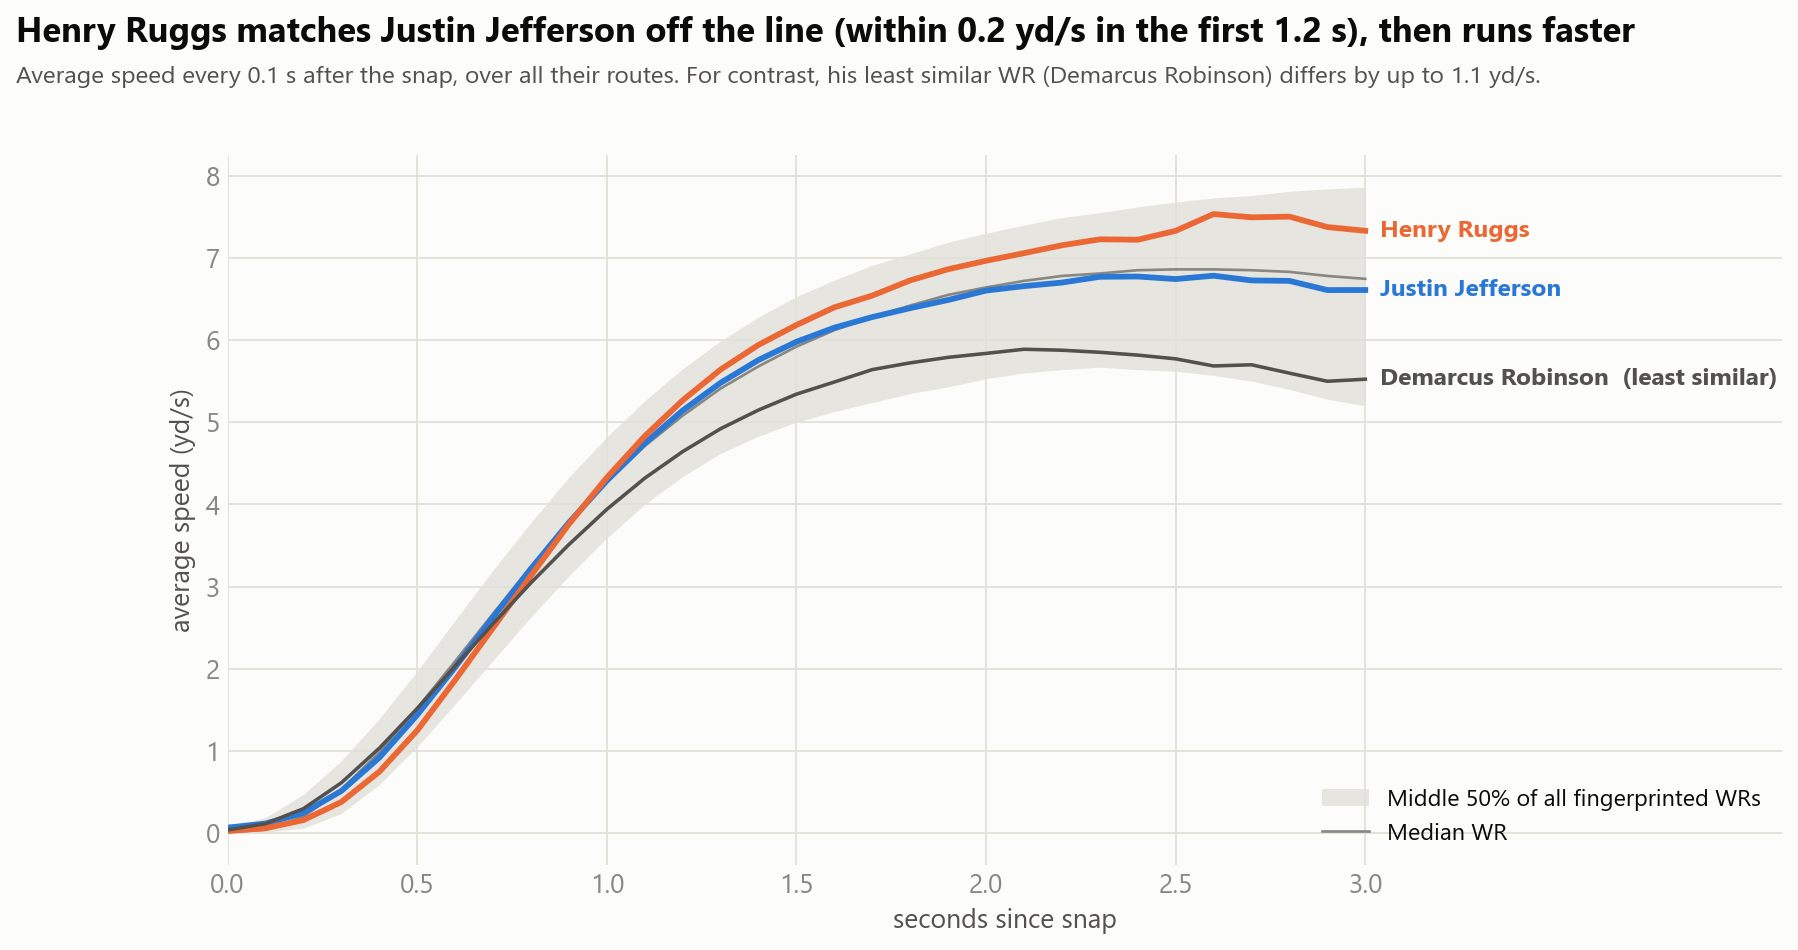

In [24]:
OTHER = "Justin Jefferson"
visuals.compare_matches(d, OTHER)
display(Image(OUT / f"compare_{visuals.slug(OTHER)}_top6.png", width=1000))
best = pairs[(pairs.displayName == OTHER) & (pairs["rank"] == 1)].match_displayName.iloc[0]
visuals.speed_profile(d, OTHER, best)
display(Image(OUT / f"speed_profile_{visuals.slug(OTHER)}_vs_{visuals.slug(best)}.png", width=900))

## 9. Did we deliver the core idea?

A check of each promise from the project plan, computed from the outputs above (not typed in by hand).

In [25]:
clf = pd.read_csv(OUT / "classifier_summary.csv").set_index("test")
abl = pd.read_csv(OUT / "ablation.csv").set_index("fingerprint")
bud = pd.read_csv(OUT / "budget_doppelgangers.csv")
top = pairs[(pairs["rank"] <= 5) & pairs["stable"] & ~pairs["is_hub"] & ~pairs["match_is_hub"]]
stable_pairs = {tuple(sorted(p)) for p in zip(top.displayName, top.match_displayName)}
kupp = bud.set_index("star").loc["Cooper Kupp"]
split1 = clf.loc["Split-half fingerprint, top-1"]
team = clf.loc["Split-half fingerprint, teammates only"]
no_rt = abl.loc["Without route time (QB timing)"]
pos_cols = [c for c in features.FEATURES if c in ("x", "y") or "align" in c or "position" in c]

pd.DataFrame([
    ["1. Fingerprint is real", f"Season test finds the right WR out of 110 at {split1.x_chance:.1f}x chance",
     "Delivered" if split1.x_chance > 5 else "Weak"],
    ["1. ...and personal, not scheme", f"Beats chance among teammates ({team.accuracy:.0%} vs {team.chance:.0%}); "
     f"{no_rt.top1_x:.1f}x without QB timing", "Delivered" if team.x_chance > 1.2 else "Weak"],
    ["2. Doppelgängers", f"Top matches for all {pairs.displayName.nunique()} WRs; {len(stable_pairs)} stable "
     "non-hub pairs", "Delivered, few stable"],
    ["3. Budget doppelgängers", f"{len(bud)} stars matched; best stable: Cooper Kupp -> {kupp.doppelganger}, "
     f"${kupp.savings:.1f}M/yr cheaper", "Delivered, 1 stable"],
    ["Rule: HOW not WHERE", f"Field-position features used: {pos_cols or 'none'}",
     "Kept" if not pos_cols else "Broken"],
    ["Rule: WRs on pass routes only", f"{train.nflId.nunique()} WRs, all from officialPosition = WR and "
     "pff_role = Pass Route", "Kept"],
], columns=["Goal", "Evidence", "Status"]).style.hide(axis="index")

Goal,Evidence,Status
1. Fingerprint is real,Season test finds the right WR out of 110 at 11.4x chance,Delivered
"1. ...and personal, not scheme",Beats chance among teammates (53% vs 32%); 11.0x without QB timing,Delivered
2. Doppelgängers,Top matches for all 110 WRs; 5 stable non-hub pairs,"Delivered, few stable"
3. Budget doppelgängers,"15 stars matched; best stable: Cooper Kupp -> K.J. Osborn, $14.9M/yr cheaper","Delivered, 1 stable"
Rule: HOW not WHERE,Field-position features used: none,Kept
Rule: WRs on pass routes only,"209 WRs, all from officialPosition = WR and pff_role = Pass Route",Kept


## Takeaways

- **Movement style is real and measurable.** From half a season, we identify a receiver at about 11x chance, he still
  beats chance among his own teammates, and it holds without the QB-timing feature.
- **It is mostly about speed.** Release burst and top speed carry most of the signal; cuts and path shape add a
  smaller part.
- **Similar movement does not cost the same.** Pay is unrelated to where a receiver sits on the map.
- **Be careful with single matches.** Only a few doppelgänger pairs hold up when we split the games in half.
  Cooper Kupp → K.J. Osborn is the strongest budget match: stable, similar build, about $14.9M a year cheaper.